***QUICKBITE CASE STUDY BY NIKHIL KUSHWAHA***

**1. Business Background**

QuickBite is a food-delivery startup operating in 10 Indian cities across three city tiers. After three years of growth, the leadership team has noticed three things:
- Revenue is growing, but it seems to come from a small group of heavy users.
- Delivery times feel inconsistent, and some customers rate the service poorly.
- The customer database has gaps and obvious data-entry errors, so nobody trusts the numbers.

You have joined the analytics team as a **Data Analyst**. The Head of Growth has given you a customer-level extract and asked you to clean it, understand it, and report what drives customer spending.

**2. Problem Statement**

*Who are our customers, how do they spend, and which customer attributes are associated with higher annual spend? Before answering, make sure the data is clean enough to trust.*
1. How much of our data is missing or wrong, and how did you fix it?
2. What do the distributions of delivery time, order value, ratings and spend look like?
3. Which variables move together with annual_spend ?
4. How concentrated is our revenue (does a small share of customers drive most of it)?
5. How likely is a customer to wait more than 45 minutes for a delivery?

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
!pip install category_encoders
from category_encoders import TargetEncoder

****TASKS****

**Task 0: Setup and First Look**
- Load the CSV, convert signup_date to datetime.
- Use .head() , .info() , .describe() , .shape .
- Report the missing-value count and percentage per column (a Seaborn heatmap of df.isna() is a nice visual).

In [2]:
raw_df = pd.read_csv('quickbite_customers.csv')
df = raw_df.copy()
# Converting signup_date to datetime
df['signup_date'] = pd.to_datetime(df['signup_date'])

In [3]:
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   gender                  1894 non-null   object        
 5   device_type             2000 non-null   object        
 6   acquisition_channel     2000 non-null   object        
 7   age                     1861 non-null   float64       
 8   tenure_months           2000 non-null   float64       
 9   app_sessions_per_month  2000 non-null   int64         
 10  delivery_time_min       1920 non-null   float64       
 11  avg_order_value         1892 non-null   float64       
 12  customer_rating         1742 non-null   float64 

In [5]:
df.describe()

,signup_date,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
count,2000,2000.000000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000.00000,2000.000000
mean,2024-05-28 18:57:35.999999744,1.600500,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,34.89650,12995.852000
min,2023-01-01 00:00:00,1.000000,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,5.00000,523.000000
25%,2023-09-18 18:00:00,1.000000,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,17.00000,4085.750000
50%,2024-05-29 12:00:00,1.000000,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,24.00000,7142.000000
75%,2025-02-15 06:00:00,2.000000,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,32.00000,12781.250000
max,2025-11-05 00:00:00,3.000000,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,400.00000,855443.000000
std,NaN,0.772138,7.619334,9.981302,3.77856,19.486015,1133.673898,0.609572,9.483931,18.983606,49.27424,30336.382856


In [6]:
df.shape

(2000, 18)

In [7]:
df.isnull().sum()

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,106
device_type,0
acquisition_channel,0
age,139
tenure_months,0
app_sessions_per_month,0


In [8]:
missing_pct = df.isnull().sum()/df.shape[0]*100
missing_pct[missing_pct>0]

,0
gender,5.30
age,6.95
delivery_time_min,4.00
avg_order_value,5.40
customer_rating,12.90
discount_used_pct,5.20


6 out of 18 columns contain missing values across your 2,000-row dataset, with customer_rating showing the highest missingness at 12.90% (258 rows). All other 12 columns are 100% complete.


- customer_rating:	258, 12.90%,	Numerical(Satisfaction)
- age:	139,	6.95%,	Numerical(Demographic)
- avg_order_value:	108,	5.40%,	Numerical(Financial)
- gender:	106,	5.30%,	Categorical(Demographic)
- discount_used_pct:	104,	5.20%,	Numerical(Promotional)
- delivery_time_min:	80,	4.00%,	Numerical(Operational)




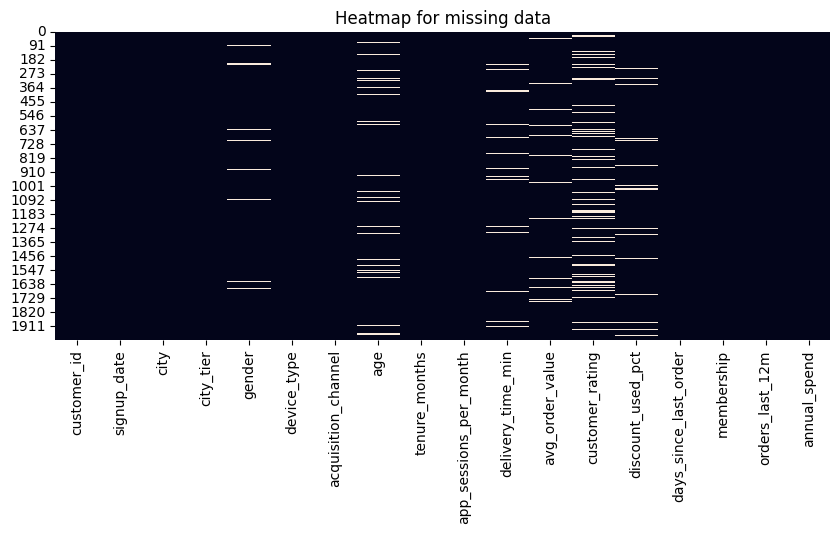

In [9]:
plt.figure(figsize=(10,4))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Heatmap for missing data")
plt.show()

Seaborn heatmap of df.isna() is a nice visual:

Yes, heatmap maps the exact grid of your dataset (rows by columns). It lets you inspect all 18 features simultaneously rather than reading separate summary tables.

---
---

**Task 1: Missing Value Imputation**

In [10]:
#columns with nulls
df.columns[df.isnull().any()]

Index(['gender', 'age', 'delivery_time_min', 'avg_order_value',
       'customer_rating', 'discount_used_pct'],
      dtype='object')

####Column: Age
####Approach: Fill with median (after outlier treatment)
####Reflect on: Why median, not mean?

In [11]:
df.age.isna().sum()

np.int64(139)

In [12]:
df.age.describe()

,age
count,1861.000000
mean,31.926384
std,7.619334
min,0.000000
25%,27.000000
50%,32.000000
75%,37.000000
max,150.000000


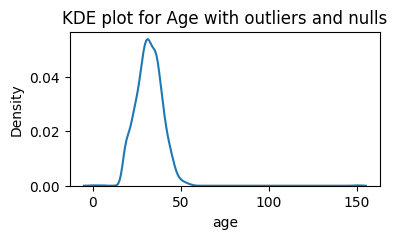

In [13]:
plt.figure(figsize=(4,2))
sns.kdeplot(df.age)
plt.title("KDE plot for Age with outliers and nulls")
plt.show()

###### We are choosing median over mean here because the outliers present in this column will drastically pull the mean, whereas the median stays completely unbothered by those anomalies. However, before imputing, we will treat the outliers across our numerical columns first—once those extreme values are handled, we will fill these missing entries with a clean, reliable median in TASK-2.

---

####Column: delivery_time_min
####Approach: Fill with median (right-skewed)
####Reflect on: What would the mean do here?

In [14]:
df.delivery_time_min.isna().sum()

np.int64(80)

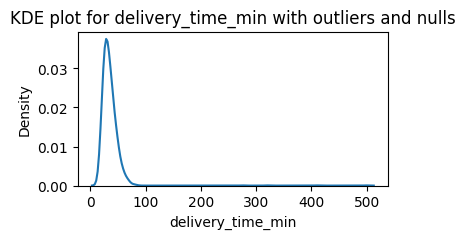

In [15]:
plt.figure(figsize=(4,2))
sns.kdeplot(df.delivery_time_min)
plt.title("KDE plot for delivery_time_min with outliers and nulls")
plt.show()

###### The density plot for delivery_time_min is right-skewed, which clearly signals the presence of extreme outliers on the higher end. Because these anomalies will heavily pull the mean, using the median is the much safer choice here. However, to keep our baseline metrics pure, we will hold off on filling these missing values for now—once we handle the outliers first, we will carry out the clean median imputation in Task-2.

---

####Column: avg_order_value
####Approach: Fill with median grouped by city_tier
####Reflect on: Group-wise vs global fill

In [16]:
df.avg_order_value.isna().sum()

np.int64(108)

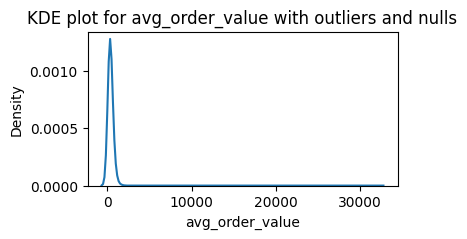

In [17]:
plt.figure(figsize=(4,2))
sns.kdeplot(df.avg_order_value)
plt.title("KDE plot for avg_order_value with outliers and nulls")
plt.show()

In [18]:
df.avg_order_value.median()

315.5

In [19]:
df.avg_order_value.groupby(df.city_tier).median()

,avg_order_value
city_tier,
1,326.0
2,309.0
3,289.5


###### Group-Wise vs. Global Fill (avg_order_value):
Columns like avg_order_value behave differently across underlying segments—specifically city_tier, where spending baselines vary noticeably between Tier 1, Tier 2, and Tier 3 cities. Using a simple global median would flatten these distinct spending patterns into a single, biased number dominated by Tier 1 orders. Therefore, instead of a global fill, we are going with group-wise median imputation per city_tier (after treating outliers) so each segment retains its true economic baseline.

###### Above analysis revealed distinct spending baselines across city tiers, with median order values dropping from Tier 1 (326.0) to Tier 3 (289.5). Plus, Imputation will be done after outlier treatment in Task-2
---


####Column: customer_rating
####Approach: Fill with median (left-skewed); compare with group median by city_tier
####Reflect on: Is missingness related to long delivery times?




In [20]:
df.customer_rating.isna().sum()

np.int64(258)

In [21]:
df.customer_rating.describe()

,customer_rating
count,1742.000000
mean,4.290356
std,0.609572
min,1.000000
25%,4.000000
50%,4.400000
75%,4.700000
max,5.000000


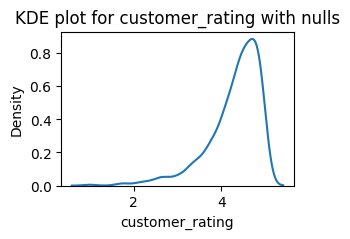

In [22]:
plt.figure(figsize=(3,2))
sns.kdeplot(df.customer_rating)
plt.title("KDE plot for customer_rating with nulls")
plt.show()

In [23]:
# before moving forward to imputation in order to solve missingness(nulls) it could be because of no ratings due to unsatisfaction
df['unsatisfactory_delivery'] = df['customer_rating'].isna()

In [24]:
df.groupby('unsatisfactory_delivery')['delivery_time_min'].describe()

,count,mean,std,min,25%,50%,75%,max
unsatisfactory_delivery,,,,,,,,
False,1669.0,34.011384,20.295603,15.6,25.6,30.8,38.80,500.0
True,251.0,41.506375,10.831149,17.6,35.8,40.0,47.15,83.9


###### Rated deliveries having mean time of approx 34 mins and 50% deliveries made under 30 mins which are quiet satisfactory, whereas for missing records mean and median took +10 mins longer than rated which could result in customers left rating part out of frustration. Still this might be random missing because the delivery column still contains outliers which can be seen in rated's max(500) which hindered mean and std. So, before concluding anything we'll treat delivery_time_min columns first in TASK-2 to conclude.

In [25]:
df.customer_rating.median()

4.4

In [26]:
df.customer_rating.groupby(df.city_tier).median()

,customer_rating
city_tier,
1,4.4
2,4.5
3,4.4


###### all 3 medians seggregated by city_tier seems almost same ranging 4.4, 4.5, 4.4. Therefore, sticking with global median will not be a problem.

In [27]:
df.customer_rating = df.customer_rating.fillna(df.customer_rating.median())

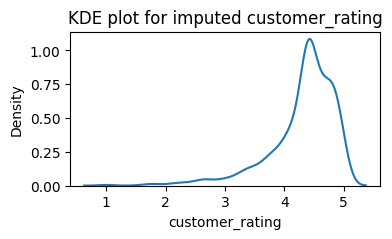

In [28]:
plt.figure(figsize=(4,2))
sns.kdeplot(df.customer_rating)
plt.title("KDE plot for imputed customer_rating")
plt.show()

---

####Column: discount_used_pct
####Approach:  Fill with mean or median
####Reflect on: Compare both


In [29]:
df.discount_used_pct.isna().sum()

np.int64(104)

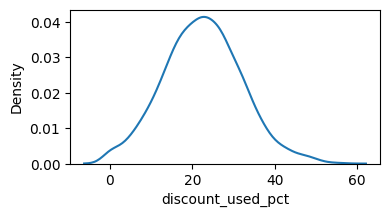

In [30]:
plt.figure(figsize=(4,2))
sns.kdeplot(df.discount_used_pct)
plt.show()

In [31]:
df['discount_used_pct'].describe()

,discount_used_pct
count,1896.000000
mean,22.499947
std,9.483931
min,0.000000
25%,16.200000
50%,22.400000
75%,28.500000
max,55.900000


Observation & Imputation Strategy:

Looking at the descriptive stats for discount_used_pct, the distribution is symmetrical and completely free of impossible anomalies—the mean (22.50%) and median (22.40%) sit almost identical to each other, and the range (0% to 55.9%) aligns with realistic promotional discount limits. Because there are no extreme outliers pulling the distribution, we don't need outlier removal or capping here, and we can safely impute the 104 missing entries using the mean.

In [32]:
df.discount_used_pct = df.discount_used_pct.fillna(df.discount_used_pct.mean())

In [33]:
df['discount_used_pct'].describe()

,discount_used_pct
count,2000.000000
mean,22.499947
std,9.233931
min,0.000000
25%,16.400000
50%,22.499947
75%,28.200000
max,55.900000


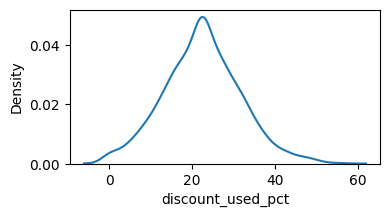

In [34]:
plt.figure(figsize=(4,2))
sns.kdeplot(df.discount_used_pct)
plt.show()

###### We chose the mean over the median here because no outliers or anomalies were detected, and the density plot shows a clean, bell-shaped curve. Since the distribution is symmetrical and the mean sits almost identical to the median, using the mean accurately represents the center of the data without any risk of skew distortion.

---

####Column: Gender
####Approach: Fill with mode, or a new "Unknown" category
####Reflect on: Which is more honest?

In [35]:
df.gender.isna().sum()

np.int64(106)

In [36]:
df.gender.value_counts()

,count
gender,
Male,1023
Female,836
Other,35


Observation:

Male is the most frequent category with 1,023 entries (54.01% of valid records), followed by Female at 836 entries (44.14%), and Other at 35 entries (1.85%).

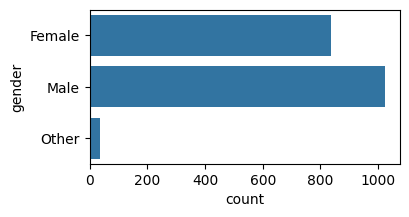

In [37]:
plt.figure(figsize=(4,2))
sns.countplot(df.gender)
plt.show()

In [38]:
global_mode=df['gender'].mode()[0]
df['gender'] = df['gender'].fillna(global_mode)

In [39]:
df.gender.isna().sum()

np.int64(0)

######  'Other' already exists as a valid third option and missingness is low (5.30%), introducing a fourth 'Unknown' bucket adds unnecessary cardinality and splits the data artificially. Imputing with the mode ('Male') keeps the existing category structure intact.
---

In [40]:
df.isna().sum()

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,0
device_type,0
acquisition_channel,0
age,139
tenure_months,0
app_sessions_per_month,0


*left age, delivery_min_time and avg_order_value because of presence of major outliers*


---
---

**Task 2: Outlier Detection and Removal**
- Plot box plots for age, delivery_time_min, avg_order_value.
- Apply the IQR rule (below Q1 − 1.5×IQR or above Q3 + 1.5×IQR).
- Apply the Z-score rule (|z| > 3) and compare it with IQR.
- Decide for each column: remove, cap (winsorise), or keep. Justify it.

(Hint: an age of 150 is an error, but a 500-minute delivery might be a real failure worth investigating, and a very high spend might be a genuine VIP.)
- Show box plots before and after.

Suggested order: handle impossible values and outliers first, then compute imputation medians so extreme values don't distort them.

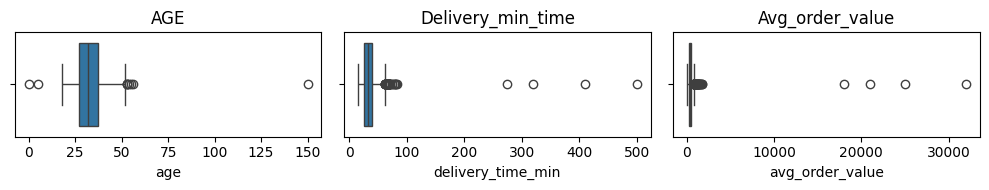

In [41]:
# box plots of age, delivery_min_time and avg_order_value
fig, (ax1, ax2, ax3)= plt.subplots(1, 3, figsize=(10, 2))
sns.boxplot(df.age, orient='h', ax=ax1)
sns.boxplot(df.delivery_time_min, orient='h', ax=ax2)
sns.boxplot(df.avg_order_value, orient='h', ax=ax3)
ax1.set_title('AGE')
ax2.set_title('Delivery_min_time')
ax3.set_title('Avg_order_value')
plt.tight_layout()
plt.show()


In [42]:
# outlier treatment method
class outlier_treatment:

  def __init__(self, col):
    self.raw_data = col.copy()
    valid_data = col.dropna()

    # ZSCORE metrics
    mean = valid_data.mean()
    std = valid_data.std()
    self.lower_z = mean-3*std
    self.upper_z = mean+3*std

    # IQR metrics
    q1 = valid_data.quantile(0.25)
    q3 = valid_data.quantile(0.75)
    iqr = q3-q1
    self.lower_iqr = q1-1.5*iqr
    self.upper_iqr = q3+1.5*iqr

  def iqr_capping(self):
    return self.raw_data.clip(lower=self.lower_iqr, upper=self.upper_iqr) #to leave nulls/nan as it is

  def Zscore_capping(self):
    return self.raw_data.clip(lower=self.lower_z, upper=self.upper_z)

  def iqr_removing(self):
    mask = (self.raw_data>=self.lower_iqr) & (self.raw_data<=self.upper_iqr) | self.raw_data.isna()
    return self.raw_data[mask]

  def Zscore_removing(self):
    mask = (self.raw_data>=self.lower_z) & (self.raw_data<=self.upper_z) | self.raw_data.isna()
    return self.raw_data[mask]




***Column: Age***

*Outlier treatment and imputation*


In [43]:
df.age.describe()

,age
count,1861.000000
mean,31.926384
std,7.619334
min,0.000000
25%,27.000000
50%,32.000000
75%,37.000000
max,150.000000


In [44]:
age=outlier_treatment(df['age'])

In [45]:
# outliers capping - iqr vs zscore
print("length after capping outliers df.age with iqr:", len(age.iqr_capping()))
print("length after capping outliers df.age with Zscore:", len(age.Zscore_capping()))
print()
print("Stats after capping outliers df.age with iqr:")
print(age.iqr_capping().describe())
print()
print("Stats after capping outliers df.age with Zscore:")
print(age.Zscore_capping().describe())

length after capping outliers df.age with iqr: 2000
length after capping outliers df.age with Zscore: 2000

Stats after capping outliers df.age with iqr:
count    1861.000000
mean       31.877485
std         7.070082
min        12.000000
25%        27.000000
50%        32.000000
75%        37.000000
max        52.000000
Name: age, dtype: float64

Stats after capping outliers df.age with Zscore:
count    1861.000000
mean       31.881510
std         7.101112
min         9.068381
25%        27.000000
50%        32.000000
75%        37.000000
max        54.784387
Name: age, dtype: float64


In [46]:
# outlier removal - iqr vs zscore
print("length after removing outliers df.age with iqr:", len(age.iqr_removing()))
print("length after removing outliers df.age with Zscore:", len(age.Zscore_removing()))
print()
print("Stats after removing outliers df.age with iqr:")
print(age.iqr_removing().describe())
print()
print("Stats after removing outliers df.age with Zscore:")
print(age.Zscore_removing().describe())

length after removing outliers df.age with iqr: 1991
length after removing outliers df.age with Zscore: 1995

Stats after removing outliers df.age with iqr:
count    1852.000000
mean       31.822894
std         6.947511
min        18.000000
25%        27.000000
50%        32.000000
75%        37.000000
max        52.000000
Name: age, dtype: float64

Stats after removing outliers df.age with Zscore:
count    1856.000000
mean       31.869073
std         7.010857
min        18.000000
25%        27.000000
50%        32.000000
75%        37.000000
max        54.000000
Name: age, dtype: float64


###### We selected outlier removal over capping because the column contains impossible data entry errors (such as 0 and 150). Capping would retain these invalid records by forcing them into artificial boundary values (12 or 52), which would distort our analysis. Given our baseline of 1,861 valid entries, dropping these extreme rows preserves data integrity without causing data loss.
Furthermore, we chose the IQR method over the Z-score method because extreme anomalies heavily inflate the mean and std, stretching Z-score metric too wide. Whereas, IQR relies on quartiles and the median, keeping our boundaries robust and unaffected by severe outliers.

In [47]:
df.age = age.iqr_removing()

In [48]:
# imputing age column with median
median_age = df.age.median()
df.age = df.age.fillna(median_age)

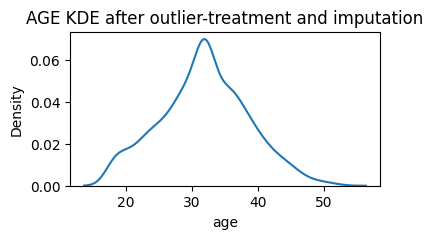

In [49]:
# KDE plot after outlier treatment
plt.figure(figsize=(4,2))
sns.kdeplot(df.age)
plt.title('AGE KDE after outlier-treatment and imputation')
plt.show()

---

***Column: delivery_time_min***

*Outlier treatment and imputation*

In [50]:
df.delivery_time_min.describe()

,delivery_time_min
count,1920.000000
mean,34.991198
std,19.486015
min,15.600000
25%,26.200000
50%,32.250000
75%,40.500000
max,500.000000


In [51]:
delivery_time_min=outlier_treatment(df['delivery_time_min'])

In [52]:
# outliers capping - iqr vs zscore
print("length after capping outliers df.delivery_time_min with iqr:", len(delivery_time_min.iqr_capping()))
print("length after capping outliers df.delivery_time_min with Zscore:", len(delivery_time_min.Zscore_capping()))
print()
print("Stats after capping outliers df.delivery_time_min with iqr:")
print(delivery_time_min.iqr_capping().describe())
print()
print("Stats after capping outliers df.delivery_time_min with Zscore:")
print(delivery_time_min.Zscore_capping().describe())

length after capping outliers df.delivery_time_min with iqr: 2000
length after capping outliers df.delivery_time_min with Zscore: 2000

Stats after capping outliers df.delivery_time_min with iqr:
count    1920.000000
mean       34.195885
std        10.637779
min        15.600000
25%        26.200000
50%        32.250000
75%        40.500000
max        61.950000
Name: delivery_time_min, dtype: float64

Stats after capping outliers df.delivery_time_min with Zscore:
count    1920.000000
mean       34.402030
std        11.321198
min        15.600000
25%        26.200000
50%        32.250000
75%        40.500000
max        93.449242
Name: delivery_time_min, dtype: float64


In [53]:
# outlier removal - iqr vs zscore
print("length after removing outliers df.delivery_time_min with iqr:", len(delivery_time_min.iqr_removing()))
print("length after removing outliers df.delivery_time_min with Zscore:", len(delivery_time_min.Zscore_removing()))
print()
print("Stats after removing outliers df.delivery_time_min with iqr:")
print(delivery_time_min.iqr_removing().describe())
print()
print("Stats after removing outliers df.delivery_time_min with Zscore:")
print(delivery_time_min.Zscore_removing().describe())

length after removing outliers df.delivery_time_min with iqr: 1954
length after removing outliers df.delivery_time_min with Zscore: 1996

Stats after removing outliers df.delivery_time_min with iqr:
count    1874.000000
mean       33.514621
std         9.826455
min        15.600000
25%        26.100000
50%        31.900000
75%        39.775000
max        61.800000
Name: delivery_time_min, dtype: float64

Stats after removing outliers df.delivery_time_min with Zscore:
count    1916.000000
mean       34.278758
std        11.006333
min        15.600000
25%        26.200000
50%        32.200000
75%        40.400000
max        83.900000
Name: delivery_time_min, dtype: float64


In [54]:
print(df['delivery_time_min'][df['delivery_time_min']>100].sort_values())
print(df['delivery_time_min'][df['delivery_time_min']<18].sort_values())

1223    275.0
1293    320.0
1210    410.0
1417    500.0
Name: delivery_time_min, dtype: float64
254     15.6
759     15.8
1352    15.8
81      15.9
69      15.9
690     16.0
168     16.1
522     16.2
1836    16.2
1181    16.4
414     16.4
1756    16.4
1885    16.4
102     16.6
1525    16.7
1728    16.7
1729    16.8
1005    16.8
1001    16.9
704     17.1
1659    17.1
793     17.2
538     17.2
154     17.2
1009    17.3
1641    17.3
1054    17.4
720     17.4
1312    17.4
1962    17.4
1136    17.5
628     17.5
1369    17.6
1503    17.6
1963    17.6
1586    17.9
Name: delivery_time_min, dtype: float64


###### Here, we're going with IQR capping instead of removal because we only have 4 extreme anomalies (275, 320, 410, and 500 minutes) representing app failures or system errors, while values below 18 minutes represent genuine VIP or fast deliveries. Leaving these extreme values as they are would corrupt our analysis, as outliers like 500 heavily distorted the mean and inflated the Z-score standard deviation up to 11.32.
###### Choosing capping over removal is the right call here because iqr_removing drops 46 rows (reducing our count from 2000 to 1954), which doesn't just remove the 4 system failures—it also wipes out 42 legitimate long delivery times (62–80 minutes) caused by normal peak-hour delays. With IQR capping, we preserve all 2000 rows and keep our VIP deliveries intact, while cleanly pulling those 4 extreme failures down to a realistic upper threshold of 61.95 minutes without losing the rest of the valid data in those rows.

In [55]:
df['delivery_time_min'] = delivery_time_min.iqr_capping()

In [56]:
# imputation
dtm_median = df.delivery_time_min.median()
df['delivery_time_min'] = df.delivery_time_min.fillna(dtm_median)

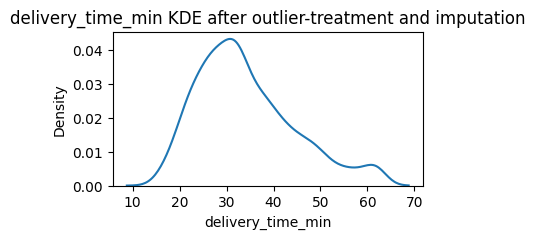

In [57]:
# KDE plot after outlier treatment
plt.figure(figsize=(4,2))
sns.kdeplot(df.delivery_time_min)
plt.title('delivery_time_min KDE after outlier-treatment and imputation')
plt.show()

**TASK 1: (Missingness in customer rating, is late delivery responsible??)**

We've removed anomalies from deliver_time_min column so now we can move forward with our conclusion on missing customer rating

In [58]:
df.groupby('unsatisfactory_delivery')['delivery_time_min'].describe()

,count,mean,std,min,25%,50%,75%,max
unsatisfactory_delivery,,,,,,,,
False,1742.0,33.114122,10.133836,15.6,25.925,31.4,38.100,61.95
True,258.0,40.896512,9.872303,17.6,35.500,39.9,46.975,61.95


Conclusion: What started as an initial hunch came out to be a solid, data-backed finding. After treating outliers and imputing delivery_time_min, the pattern is clear: missing customer_rating entries (258 rows) are not random, but heavily concentrated among unsatisfied customers who experienced significantly slower deliveries (median 39.9 mins, mean 40.9 mins) compared to customers who rated (median 31.4 mins, mean 33.1 mins).

---

***Column: Avg_order_value***

*Outlier treatment and imputation*

In [59]:
df.avg_order_value.describe()

,avg_order_value
count,1892.000000
mean,417.577696
std,1133.673898
min,57.000000
25%,215.000000
50%,315.500000
75%,458.250000
max,32000.000000


###### from here on Avg_order_value column will be seggregatted in 3 categories Because spending patterns vary across city tiers, treating outliers globally would distort our group medians, so we analyzed and treated each city_tier separately.

In [60]:
print(df.avg_order_value[df['city_tier']==1].describe(), df.avg_order_value[df['city_tier']==1].isna().sum())
print()
print(df.avg_order_value[df['city_tier']==2].describe(), df.avg_order_value[df['city_tier']==2].isna().sum())
print()
print(df.avg_order_value[df['city_tier']==3].describe(), df.avg_order_value[df['city_tier']==3].isna().sum())

count     1100.000000
mean       473.445455
std       1475.191452
min         57.000000
25%        227.750000
50%        326.000000
75%        482.250000
max      32000.000000
Name: avg_order_value, dtype: float64 55

count     456.000000
mean      356.357456
std       204.087316
min        68.000000
25%       204.500000
50%       309.000000
75%       449.750000
max      1487.000000
Name: avg_order_value, dtype: float64 33

count     336.000000
mean      317.761905
std       183.419419
min        66.000000
25%       190.000000
50%       289.500000
75%       387.250000
max      1125.000000
Name: avg_order_value, dtype: float64 20


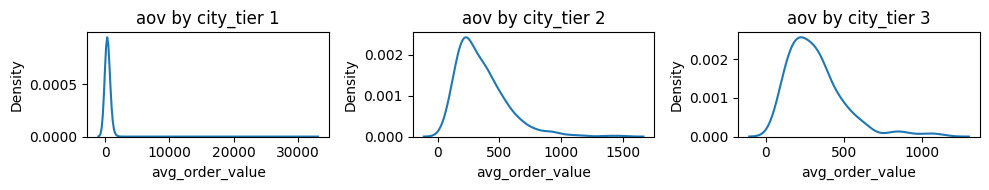

In [61]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10,2))
sns.kdeplot(df.avg_order_value[df['city_tier']==1], ax=ax1)
sns.kdeplot(df.avg_order_value[df['city_tier']==2], ax=ax2)
sns.kdeplot(df.avg_order_value[df['city_tier']==3], ax=ax3)
ax1.set_title('aov by city_tier 1')
ax2.set_title('aov by city_tier 2')
ax3.set_title('aov by city_tier 3')
plt.tight_layout()
plt.show()

In [62]:
# For city_tier 1, we're removing outliers
aov_ct1 = outlier_treatment(df.loc[df.city_tier==1, "avg_order_value"])
cleaned_aovct1 = aov_ct1.iqr_removing()
df.loc[df.city_tier==1, "avg_order_value"] = np.nan # to clean data containing outliers like 32000
df.loc[df.city_tier==1, "avg_order_value"] = cleaned_aovct1

Here, the mean (473.45) is pulled significantly higher than the median (326.00), and the std (1475.19) is heavily inflated because of an extreme order value of 32,000. A restaurant order of 32,000 when the typical spend is around 326 is a clear system glitch or logging error rather than normal customer behavior. Therefore, we went with IQR removal instead of capping so we don't force an invalid data error into an artificial upper bound, ensuring our Tier 1 median remains pure before imputation.

In [63]:
df.loc[df.city_tier==1, "avg_order_value"].describe()

,avg_order_value
count,1043.000000
mean,352.897411
std,172.529288
min,57.000000
25%,221.000000
50%,318.000000
75%,453.500000
max,862.000000


In [64]:
# For city_tier 2 and 3, I am capping by iqr though I also wanted to leave as it is because they seems genuine
aov_ct2 = outlier_treatment(df.loc[df.city_tier==2, "avg_order_value"])
aov_ct3 = outlier_treatment(df.loc[df.city_tier==3, "avg_order_value"])
cleaned_aovct2 = aov_ct2.iqr_capping()
cleaned_aovct3 = aov_ct3.iqr_capping()
df.loc[df.city_tier==2, "avg_order_value"] = cleaned_aovct2
df.loc[df.city_tier==3, "avg_order_value"] = cleaned_aovct3

Tiers 2 and 3 have completely stable std (204.09 and 183.42), with maximum order values of 1,487 and 1,125 against typical medians of 309 and 289.5. These upper values represent genuine as large family dinners or premium group orders rather than broken data. Here, we chose IQR capping over removal so we don't lose valid customer rows, while gently pulling those natural high-end tails into a realistic boundary without distorting our group-wise median imputation.


In [65]:
print(df.avg_order_value[df['city_tier']==2].describe())
print(df.avg_order_value[df['city_tier']==3].describe())

count    456.00000
mean     349.51261
std      180.87999
min       68.00000
25%      204.50000
50%      309.00000
75%      449.75000
max      817.62500
Name: avg_order_value, dtype: float64
count    336.000000
mean     308.341146
std      154.486833
min       66.000000
25%      190.000000
50%      289.500000
75%      387.250000
max      683.125000
Name: avg_order_value, dtype: float64


In [66]:
# Imputation
df['avg_order_value'] = df['avg_order_value'].fillna(
    df.groupby('city_tier')['avg_order_value'].transform('median'))

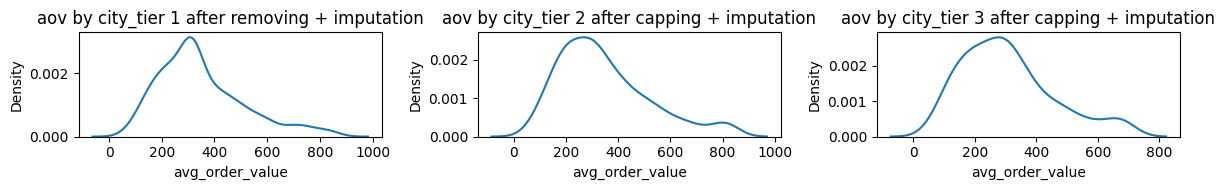

In [67]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12,2))
sns.kdeplot(df.avg_order_value[df['city_tier']==1], ax=ax1)
sns.kdeplot(df.avg_order_value[df['city_tier']==2], ax=ax2)
sns.kdeplot(df.avg_order_value[df['city_tier']==3], ax=ax3)
ax1.set_title('aov by city_tier 1 after removing + imputation')
ax2.set_title('aov by city_tier 2 after capping + imputation')
ax3.set_title('aov by city_tier 3 after capping + imputation')
plt.tight_layout()
plt.show()

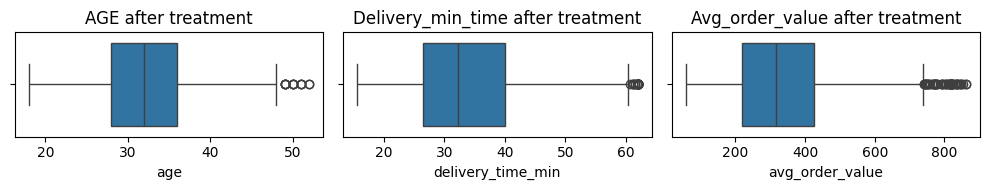

In [68]:
# box plots of age, delivery_min_time and avg_order_value 'After'
fig, (ax1, ax2, ax3)= plt.subplots(1, 3, figsize=(10, 2))
sns.boxplot(df.age, orient='h', ax=ax1)
sns.boxplot(df.delivery_time_min, orient='h', ax=ax2)
sns.boxplot(df.avg_order_value, orient='h', ax=ax3)
ax1.set_title('AGE after treatment')
ax2.set_title('Delivery_min_time after treatment')
ax3.set_title('Avg_order_value after treatment')
plt.tight_layout()
plt.show()

---
---

**Task 3: Distribution Shapes with KDE Plots**

Plot a histogram with a KDE curve for each, and label the shape:

Calculate skewness with pandas (.skew()) and show where mean, median and mode sits on each plot (vertical lines). Explain why the order of mean, median, mode flips between left- and right-skewed data.

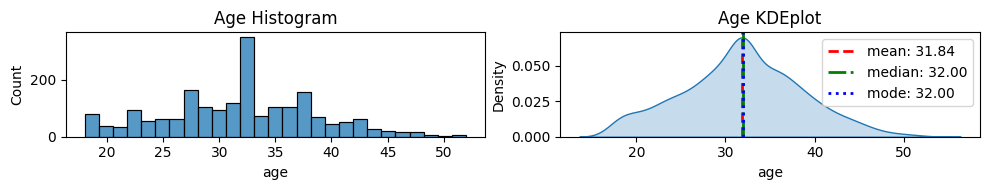

In [69]:
# Column: age | Shape: Approximately normal
mean = df.age.mean()
median = df.age.median()
mode = df.age.mode()[0] if not df.age.mode().empty else median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,2))
sns.histplot(df['age'], ax=ax1)
sns.kdeplot(df['age'], ax=ax2, fill=True)
ax1.set_title('Age Histogram')
ax2.set_title('Age KDEplot')
ax2.axvline(mean, linestyle='--', color='red', linewidth=2, label=f'mean: {mean:.2f}')
ax2.axvline(median, linestyle='-.', color='green', linewidth=2, label=f'median: {median:.2f}')
ax2.axvline(mode, linestyle=':', color='blue', linewidth=2, label=f'mode: {mode:.2f}')
ax2.legend()
plt.tight_layout()
plt.show()

In [70]:
print('Skewness of Age:', df.age.skew())

Skewness of Age: 0.05649014611289146


A skewness value of 0.0565 tells us that our cleaned age column is almost perfectly symmetrical (normally distributed). Mean, Median and Mode are overlapping seen in KDE plot

---

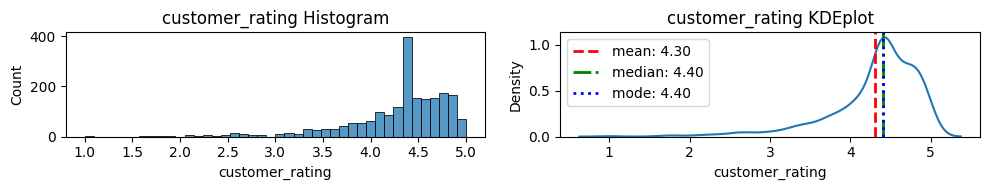

In [71]:
# Column: customer_rating | Shape: Left-skewed (negatively skewed)
mean = df.customer_rating.mean()
median = df.customer_rating.median()
mode = df.customer_rating.mode()[0] if not df.customer_rating.mode().empty else median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,2))
sns.histplot(df['customer_rating'], ax=ax1)
sns.kdeplot(df['customer_rating'], ax=ax2)
ax1.set_title('customer_rating Histogram')
ax2.set_title('customer_rating KDEplot')
ax2.axvline(mean, linestyle='--', color='red', linewidth=2, label=f'mean: {mean:.2f}')
ax2.axvline(median, linestyle='-.', color='green', linewidth=2, label=f'median: {median:.2f}')
ax2.axvline(mode, linestyle=':', color='blue', linewidth=2, label=f'mode: {mode:.2f}')
ax2.legend()
plt.tight_layout()
plt.show()

In [72]:
print('Skewness of Customer_rating:', df.customer_rating.skew())

Skewness of Customer_rating: -1.810939017213576


A skewness value of -1.81 indicates that our customer_rating column is highly negatively skewed (left-skewed).
- Most customer ratings are clustered near the top end (between 4.0 and 5.0), while a small tail of dissatisfied customers stretches down toward 1.0.
- Mean vs. Median Position: On a negatively skewed plot, the low ratings pull the mean to the left, making it lower than the median.

---

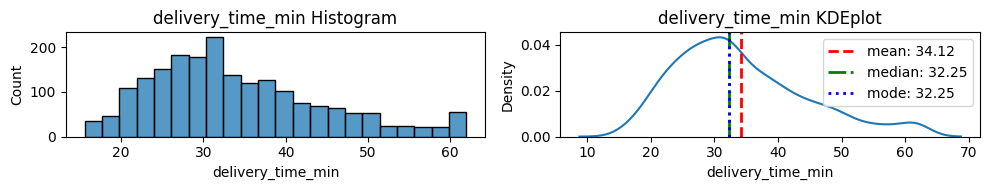

In [73]:
# Column: delivery_time_min | Shape: Moderately Right-skewed
mean = df.delivery_time_min.mean()
median = df.delivery_time_min.median()
mode = df.delivery_time_min.mode()[0] if not df.delivery_time_min.mode().empty else median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,2))
sns.histplot(df['delivery_time_min'], ax=ax1)
sns.kdeplot(df['delivery_time_min'], ax=ax2)
ax1.set_title('delivery_time_min Histogram')
ax2.set_title('delivery_time_min KDEplot')
ax2.axvline(mean, linestyle='--', color='red', linewidth=2, label=f'mean: {mean:.2f}')
ax2.axvline(median, linestyle='-.', color='green', linewidth=2, label=f'median: {median:.2f}')
ax2.axvline(mode, linestyle=':', color='blue', linewidth=2, label=f'mode: {mode:.2f}')
ax2.legend()
plt.tight_layout()
plt.show()

In [74]:
print('Skewness of Delivery_time_min:', df.delivery_time_min.skew())

Skewness of Delivery_time_min: 0.7674757669305282


A skewness value of 0.7675 indicates that our cleaned delivery_time_min column is moderately positively skewed (right-skewed).
- Mean vs. Median Position: On a positively skewed plot, the high delivery time pull the mean to the right, making it greater than the median
---

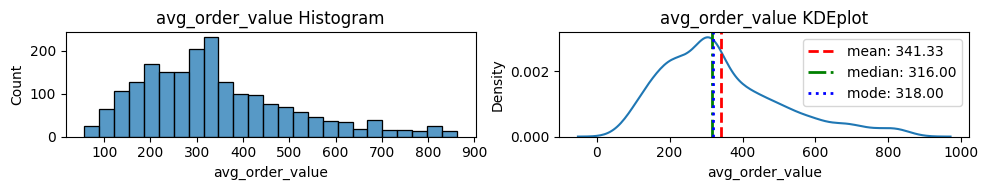

In [75]:
# Column: avg_order_value | Shape: Log-normal (apply np.log and show it becomes close to normal)
mean = df.avg_order_value.mean()
median = df.avg_order_value.median()
mode = df.avg_order_value.mode()[0] if not df.avg_order_value.mode().empty else median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,2))
sns.histplot(df['avg_order_value'], ax=ax1)
sns.kdeplot(df['avg_order_value'], ax=ax2)
ax1.set_title('avg_order_value Histogram')
ax2.set_title('avg_order_value KDEplot')
ax2.axvline(mean, linestyle='--', color='red', linewidth=2, label=f'mean: {mean:.2f}')
ax2.axvline(median, linestyle='-.', color='green', linewidth=2, label=f'median: {median:.2f}')
ax2.axvline(mode, linestyle=':', color='blue', linewidth=2, label=f'mode: {mode:.2f}')
ax2.legend()
plt.tight_layout()
plt.show()

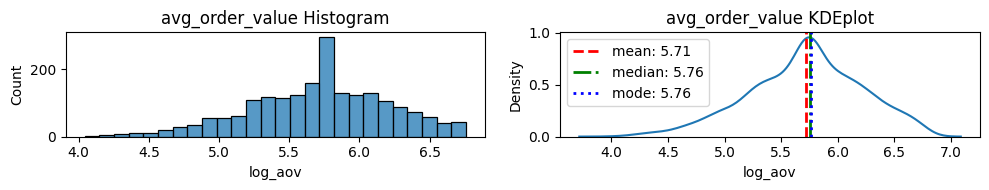

In [76]:
# applying log to average_order_value
df['log_aov'] = np.log(df['avg_order_value'])

mean = df['log_aov'].mean()
median = df['log_aov'].median()
mode = df['log_aov'].mode()[0] if not df['log_aov'].mode().empty else median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,2))
sns.histplot(df['log_aov'], ax=ax1)
sns.kdeplot(df['log_aov'], ax=ax2)
ax1.set_title('avg_order_value Histogram')
ax2.set_title('avg_order_value KDEplot')
ax2.axvline(mean, linestyle='--', color='red', linewidth=2, label=f'mean: {mean:.2f}')
ax2.axvline(median, linestyle='-.', color='green', linewidth=2, label=f'median: {median:.2f}')
ax2.axvline(mode, linestyle=':', color='blue', linewidth=2, label=f'mode: {mode:.2f}')
ax2.legend()
plt.tight_layout()
plt.show()

In [77]:
print("skewness of raw avg_order_value: ", df['avg_order_value'].skew())
print("V/S")
print("skewness of log normal avg_order_value: ", df['log_aov'].skew())

skewness of raw avg_order_value:  0.9229245531857019
V/S
skewness of log normal avg_order_value:  -0.2901758127708444


- Before Log Transformation (0.9229): After your tier-based outlier cleaning, avg_order_value still had a noticeable right tail caused by natural high-value group orders.
- After Log Transformation (-0.2902): Taking the logarithm compressed those higher order values, pulling the long right tail inward and bringing the distribution very close to a symmetric bell curve (0.0), making mean, median and mode almost equal.
---

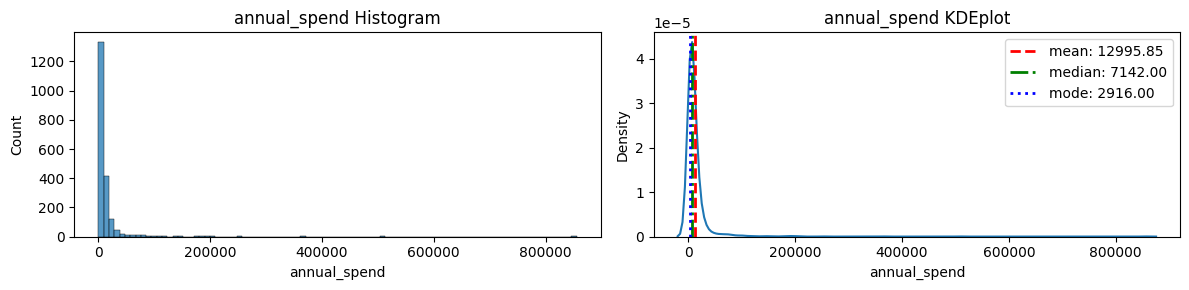

In [78]:
# Column: annual_spend | Shape: Heavy right tail (Pareto-like)
mean = df.annual_spend.mean()
median = df.annual_spend.median()
mode = df.annual_spend.mode()[0] if not df.annual_spend.mode().empty else median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,3))
sns.histplot(df['annual_spend'], ax=ax1)
sns.kdeplot(df['annual_spend'], ax=ax2)
ax1.set_title('annual_spend Histogram')
ax2.set_title('annual_spend KDEplot')
ax2.axvline(mean, linestyle='--', color='red', linewidth=2, label=f'mean: {mean:.2f}')
ax2.axvline(median, linestyle='-.', color='green', linewidth=2, label=f'median: {median:.2f}')
ax2.axvline(mode, linestyle=':', color='blue', linewidth=2, label=f'mode: {mode:.2f}')
ax2.legend()
plt.tight_layout()
plt.show()

In [79]:
print('Skewness of Annual_spend:', df.annual_spend.skew())

Skewness of Annual_spend: 15.238484519499103


A skewness of 15.24 means annual_spend is severely right-skewed(PARETO DISTRIBUTION)
- Extreme Outliers or glitch: Just like the 32,000 error we spotted in avg_order_value, one or more rows likely contain uncleaned logging mistakes or unrealistic spikes.
- True "Whale" Customers (Pareto Effect): In retail and restaurant datasets, a small fraction of VIP often spend 20x to 50x more per year than casual diners, naturally stretching financial totals.
---

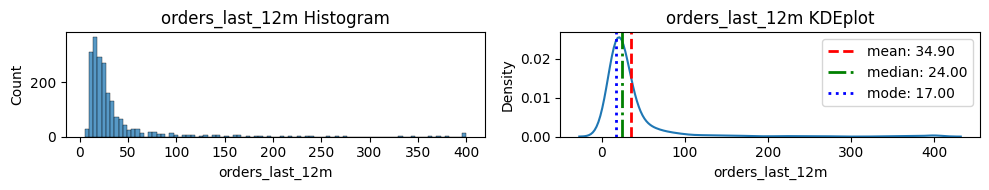

In [80]:
# Column: orders_last_12m | Shape: Heavy right tail (Pareto-like)
mean = df.orders_last_12m.mean()
median = df.orders_last_12m.median()
mode = df.orders_last_12m.mode()[0] if not df.orders_last_12m.mode().empty else median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,2))
sns.histplot(df['orders_last_12m'], ax=ax1)
sns.kdeplot(df['orders_last_12m'], ax=ax2)
ax1.set_title('orders_last_12m Histogram')
ax2.set_title('orders_last_12m KDEplot')
ax2.axvline(mean, linestyle='--', color='red', linewidth=2, label=f'mean: {mean:.2f}')
ax2.axvline(median, linestyle='-.', color='green', linewidth=2, label=f'median: {median:.2f}')
ax2.axvline(mode, linestyle=':', color='blue', linewidth=2, label=f'mode: {mode:.2f}')
ax2.legend()
plt.tight_layout()
plt.show()

In [81]:
print('Skewness of Orders_last_12m:', df.orders_last_12m.skew())

Skewness of Orders_last_12m: 5.310773032270558


A skewness value of 5.31 means orders_last_12m is heavily positively skewed (right-skewed).

---
---

**Task 4: Relationships Between Variables**
 - Covariance matrix ( df.cov() ) and correlation matrix ( df.corr() ) of numeric columns. Explain in two lines why correlation is easier to interpret than covariance.


In [82]:
# Covariance Matrix of Numeric Columns
df.cov(numeric_only=True)

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend,unsatisfactory_delivery,log_aov
city_tier,0.596198,0.067516,0.117375,0.052360,1.741982,-1.079267e+01,-0.001903,-0.156248,0.377689,9.481258e-01,-1.021972e+02,0.016544,-0.037760
age,0.067516,44.696452,0.510302,-0.363334,4.360240,-4.539237e-01,-0.013669,-15.407061,-2.244804,1.904478e+00,5.235768e+03,0.025169,-0.033238
tenure_months,0.117375,0.510302,99.626390,-0.193750,-0.361355,3.167518e+01,0.108426,-0.152214,-2.991722,-7.673531e+00,-3.633604e+03,-0.079281,0.134993
app_sessions_per_month,0.052360,-0.363334,-0.193750,14.277515,-1.584990,2.153336e+01,0.021467,-0.925968,1.871202,1.399696e+01,9.728321e+03,-0.039748,0.088608
delivery_time_min,1.741982,4.360240,-0.361355,-1.584990,108.779061,-5.789065e+01,-0.031114,-0.746203,-2.957625,-3.979947e+00,-2.540827e+03,0.874859,-0.212985
avg_order_value,-10.792673,-0.453924,31.675177,21.533362,-57.890648,2.730522e+04,-0.521898,-18.004597,-145.885954,2.484405e+02,1.080290e+06,-0.764591,78.395614
customer_rating,-0.001903,-0.013669,0.108426,0.021467,-0.031114,-5.218980e-01,0.324972,-0.015382,-0.721559,-1.854270e-01,1.489031e+01,0.012326,0.001305
discount_used_pct,-0.156248,-15.407061,-0.152214,-0.925968,-0.746203,-1.800460e+01,-0.015382,85.265478,-6.041903,5.876984e+00,-8.307425e+03,-0.029008,-0.001438
days_since_last_order,0.377689,-2.244804,-2.991722,1.871202,-2.957625,-1.458860e+02,-0.721559,-6.041903,360.377288,8.827962e+00,-9.480868e+03,-0.147909,-0.475702
orders_last_12m,0.948126,1.904478,-7.673531,13.996960,-3.979947,2.484405e+02,-0.185427,5.876984,8.827962,2.427951e+03,1.083302e+06,-0.192745,0.836304


In [83]:
# Correlation Matrix of Numeric Columns
df.corr(numeric_only=True)

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend,unsatisfactory_delivery,log_aov
city_tier,1.000000,0.013079,0.015230,0.017946,0.216310,-0.084588,-0.004324,-0.021915,0.025767,0.024920,-0.004363,0.063904,-0.098166
age,0.013079,1.000000,0.007647,-0.014383,0.062532,-0.000411,-0.003587,-0.249572,-0.017687,0.005781,0.025815,0.011228,-0.009980
tenure_months,0.015230,0.007647,1.000000,-0.005137,-0.003471,0.019205,0.019056,-0.001652,-0.015789,-0.015602,-0.012000,-0.023690,0.027149
app_sessions_per_month,0.017946,-0.014383,-0.005137,1.000000,-0.040219,0.034488,0.009966,-0.026539,0.026086,0.075177,0.084869,-0.031374,0.047073
delivery_time_min,0.216310,0.062532,-0.003471,-0.040219,1.000000,-0.033590,-0.005233,-0.007748,-0.014938,-0.007744,-0.008030,0.250180,-0.040992
avg_order_value,-0.084588,-0.000411,0.019205,0.034488,-0.033590,1.000000,-0.005540,-0.011800,-0.046506,0.030513,0.215503,-0.013800,0.952336
customer_rating,-0.004324,-0.003587,0.019056,0.009966,-0.005233,-0.005540,1.000000,-0.002922,-0.066676,-0.006601,0.000861,0.064487,0.004597
discount_used_pct,-0.021915,-0.249572,-0.001652,-0.026539,-0.007748,-0.011800,-0.002922,1.000000,-0.034467,0.012917,-0.029656,-0.009370,-0.000313
days_since_last_order,0.025767,-0.017687,-0.015789,0.026086,-0.014938,-0.046506,-0.066676,-0.034467,1.000000,0.009438,-0.016463,-0.023238,-0.050301
orders_last_12m,0.024920,0.005781,-0.015602,0.075177,-0.007744,0.030513,-0.006601,0.012917,0.009438,1.000000,0.724713,-0.011667,0.034069


correlation is relatively more easier to interpret than covariance because of its standardized range(-1 to 1) which represents exact strength while covariance is unstandardized and depends on raw units of variables(no upper or lower limit to measure strength of relation).

Just by taking glance at both above tables its clear which is easy to comprehand.

---

 - Heatmap of the correlation matrix with annotations.

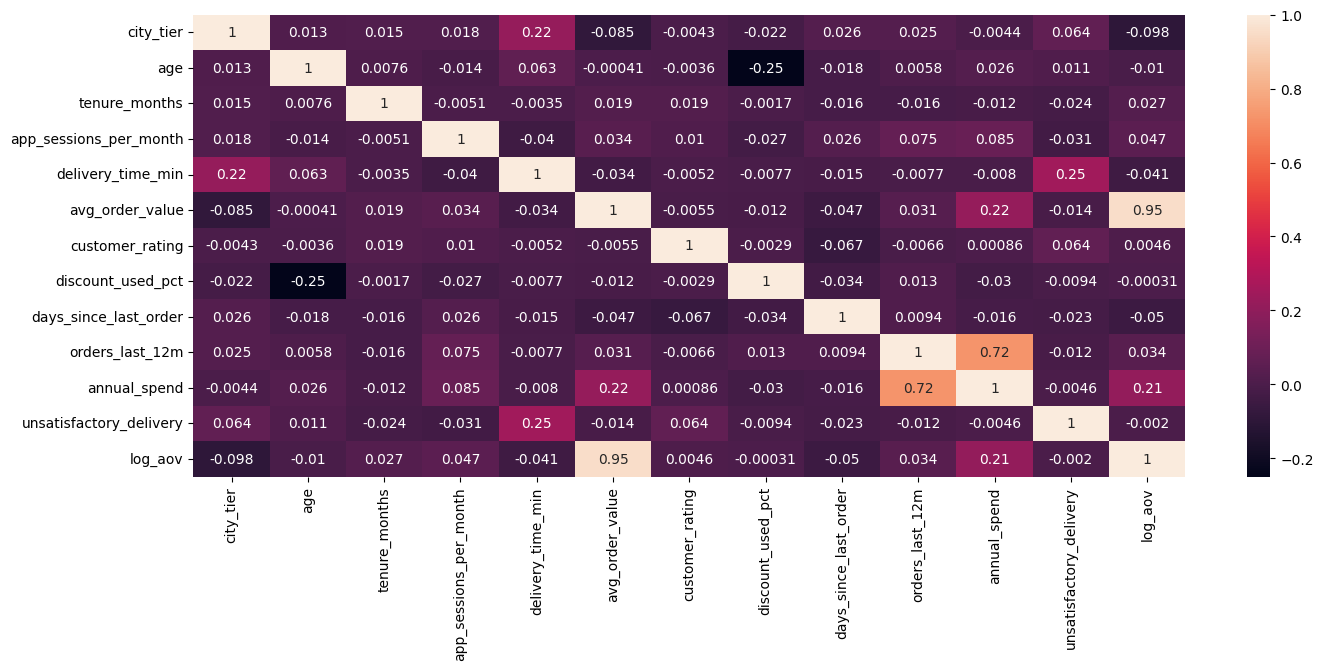

In [84]:
plt.figure(figsize=(16,6))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

KEY TAKEAWAY FROM HEATMAP:

- All columns are strongly correlated with each other with strength = 1
- discount_used_pct and city_tier is strongly negatively correlated(-0.25)
- delivery_time_min and annual_spend is strongly positively correlated(+0.22)
- unsatisfactory_delivery(created) and delivery_time_min is strongly positively correlated(+0.25)
- log_aov(created) and avg_order_value is strongly positively correlated(+0.95), obviously because log_aov is derived by avg_order_value
- annual_spend and order_last_12m is strongly positively correlated(+0.72)
- annual_spend and avg_order_value is strongly positively correlated(+0.22)

---

 - Scatter plots: orders_last_12m vs annual_spend

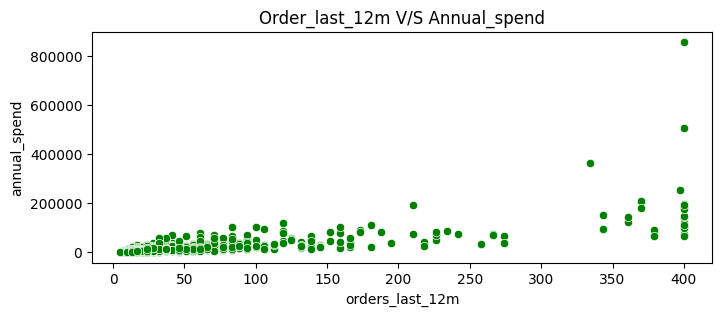

In [85]:
# SCATTERPLOT: orders_last_12m vs annual_spend
plt.figure(figsize=(8,3))
sns.scatterplot(x=df['orders_last_12m'], y=df['annual_spend'], color='green')
plt.title("Order_last_12m V/S Annual_spend")
plt.show()

*To summarize scatterplot I followed 4 point framework: Direction, Strength, Spread, and Anomalies/Clusters*

**OBSERVATION**:

The scatterplot shows a clear positive relationship between order frequency and annual spend—as the number of orders increases, total yearly spending rises accordingly. However, the data forms a widening funnel shape: at lower order counts (0–50), annual spend is tightly clustered near the bottom, whereas at higher order counts, vertical spread widens significantly due to differences in each customer's average order value.

anomalies:

• **Vertical Cap at 400 Orders**: A straight vertical stack of points sits right at orders_last_12m = 400, indicating a hard ceiling or cap on recorded order frequency.

• **Super-User Gap**: There is a noticeable empty gap between ~275 and 335 orders, separating regular customers from a small cluster of high-frequency power users (335–400 orders).

• **Extreme Spend Spikes**: At 400 orders, two extreme outliers reach roughly 500k and 850k+ in annual spend, representing high-frequency customers who also place very large orders.

Scatter plots: app_sessions_per_month vs orders_last_12m

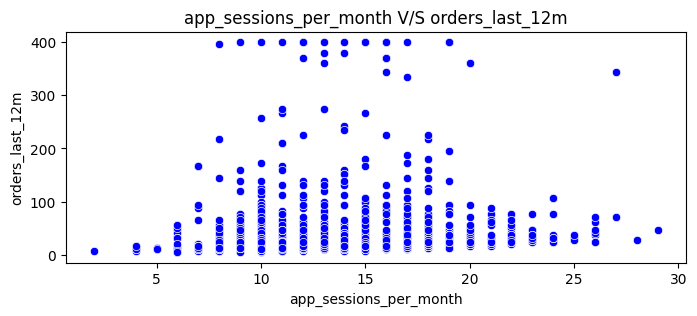

In [86]:
# SCATTERPLOT: app_sessions_per_month vs orders_last_12m
plt.figure(figsize=(8,3))
sns.scatterplot(x=df['app_sessions_per_month'], y=df['orders_last_12m'], color='blue')
plt.title("app_sessions_per_month V/S orders_last_12m")
plt.show()

**OBSERVATION**:

The scatterplot shows a non-linear, weak correlation between monthly app sessions and annual orders, forming vertical stripes because app sessions are recorded as whole integers. Rather than rising continuously, order volume peaks among moderately active users (9 to 18 sessions/month), where vertical spread widens all the way up to the 400-order ceiling. Interestingly, heavy browsers (20+ sessions/month) mostly place under 100 orders—revealing a segment of frequent "window shoppers" who open the app regularly without converting, offering a clear opportunity for targeted discount.

Scatter plots: delivery_time_min vs customer_rating.

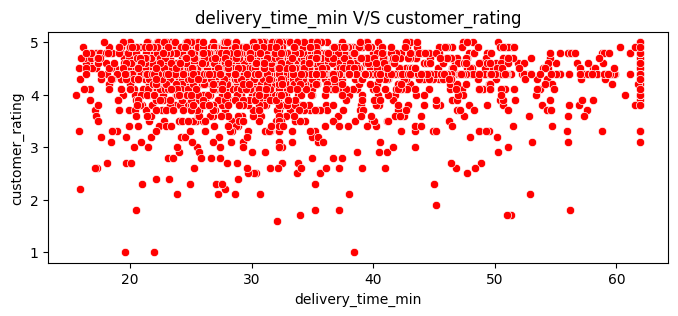

In [87]:
# SCATTERPLOT: delivery_time_min vs customer_rating
plt.figure(figsize=(8,3))
sns.scatterplot(x=df['delivery_time_min'], y=df['customer_rating'], color='red')
plt.title("delivery_time_min V/S customer_rating")
plt.show()

**OBSERVATION**:

The scatterplot shows a very weak, nearly flat relationship between delivery time and customer ratings, with the bulk of orders clustering heavily in a dense top band between 4.0 and 5.0 stars across all delivery speeds. Low ratings (1.0–3.0) appear even on fast deliveries under 25 minutes, indicating that food quality or order accuracy also drives dissatisfaction. Notably, two preprocessing artifacts are clearly visible: a crisp vertical stack at 61.95 minutes from our IQR capping, and a noticeable horizontal line at 4.4 stars on the slower right side (45–62 mins) caused by imputing missing ratings with the median.

---

 - Line plot: number of new signups per month

In [88]:
# LINEPLOT: number of new signups per month
df['month']=df.signup_date.dt.to_period('M').astype('str') #signupdates->months->months of unique year

In [89]:
# grouping unique customer_ids per months
new_users_per_month = df.groupby('month')['customer_id'].nunique().reset_index(name='new_signups')

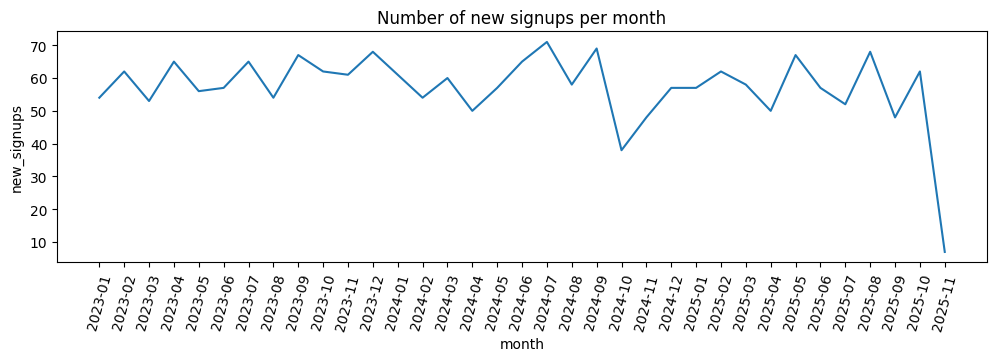

In [90]:
plt.figure(figsize=(12,3))
sns.lineplot(x=new_users_per_month['month'], y=new_users_per_month['new_signups'])
plt.xticks(rotation=75)
plt.title("Number of new signups per month")
plt.show()

In [91]:
df['signup_date'].max()

Timestamp('2025-11-05 00:00:00')

*for line chart too I followed 4 point framework(Overall Trend, Typical Baseline Range, Peaks & Dips, Edge Artifacts)*

**Observation**:

Looking at monthly customer signups from 2023-01 to 2025-11, acquisition shows a stable, flat long-term trend rather than exponential growth, fluctuating consistently within a normal band of 50 to 70 new signups per month. Signups peaked in 2024-07 (approx 71 signups) and experienced their sharpest full-month dip in 2024-10 (approx38 signups) before bouncing back to baseline. Notably, the sharp plunge in 2025-11 (~7 signups) at the far right edge is a classic partial-month artifact indicating that data collection ended early in November rather than an actual drop in business performance.

Line plot: average delivery_time_min by signup month

In [92]:
# LINEPLOT: average delivery_time_min by signup month.
# grouping avg_delivery_time per months
avg_del_time_by_signupmnth = df.groupby('month').agg(
                             avg_delivery_time=('delivery_time_min', 'mean')).reset_index(names='signup_month')

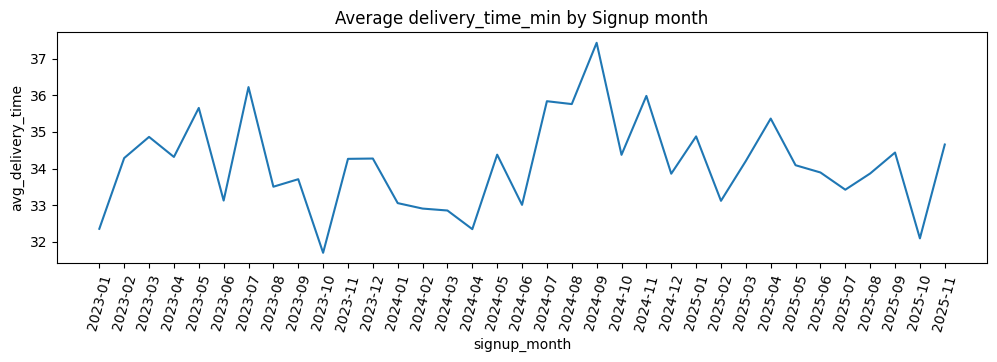

In [93]:
plt.figure(figsize=(12,3))
sns.lineplot(x=avg_del_time_by_signupmnth['signup_month'], y=avg_del_time_by_signupmnth['avg_delivery_time'])
plt.xticks(rotation=75)
plt.title("Average delivery_time_min by Signup month")
plt.show()

**Observation**:

Looking at average delivery times across customer signup (2023-01 to 2025-11), delivery speed remains stable and consistent over time with no long-term upward or downward trend. Although the line looks jagged at first glance, the Y-axis is zoomed into a very narrow band between 31.7 and 37.4 minutes—meaning almost all cohorts experience an average delivery time tightly centered around 33 to 35.5 minutes. Delivery times peaked slightly for the 2024-09 cohort (approx 37.4 mins) and hit their lowest point in 2023-10 (approx 31.7 mins), confirming that operational delivery performance has stayed reliable regardless of when a customer joined.


---

 - Box plots by category: annual_spend by membership

In [94]:
# BOXPLOT: Annual_spend by membership
df[['annual_spend', 'membership']].head()

,annual_spend,membership
0,8675.0,Basic
1,7896.0,Basic
2,1826.0,Basic
3,90202.0,Basic
4,2773.0,Basic


In [95]:
df['membership'].unique()

array(['Basic', 'Silver', 'Platinum', 'Gold'], dtype=object)

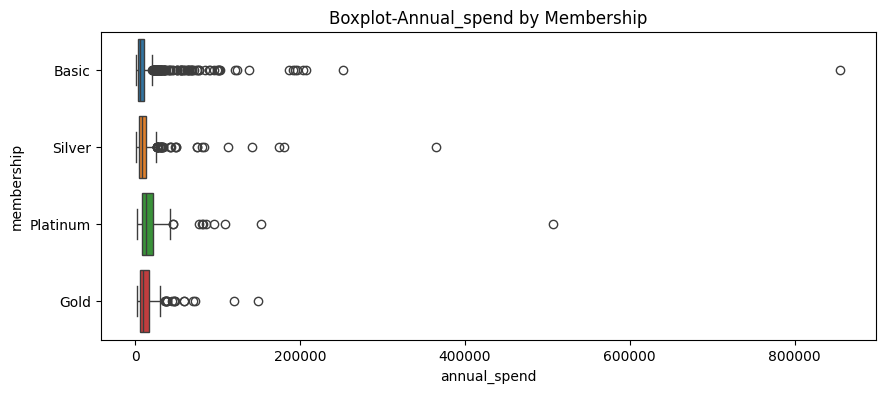

In [96]:
plt.figure(figsize=(10,4))

sns.boxplot(x = df['annual_spend'],
            y = df['membership'],
            hue = df['membership'],
            )
plt.title("Boxplot-Annual_spend by Membership")
plt.show()

**Observation**:

Comparing annual spend across membership tiers shows a clear upward progression in typical spending: both the median line and the interquartile range (box width) shift steadily to the right from Basic to Silver, Gold, and Platinum, confirming that higher-tier members spend more on average and show wider spending variation. However, all four tiers exhibit heavy right-skew with numerous high-value outliers stretching past 100,000—which compresses the main boxes tightly to the left. Most notably, our single highest-spending customer (~850k+) is still on a Basic membership alongside another ~365k spender in Silver. *A major opportunity to target these high-value unupgraded customers with VIP Platinum conversion offers*.

Box plots by category: delivery_time_min by city_tier

In [97]:
df[['delivery_time_min', 'city_tier']].head()

,delivery_time_min,city_tier
0,45.3,2
1,21.9,1
2,47.9,3
3,26.4,2
4,19.4,1


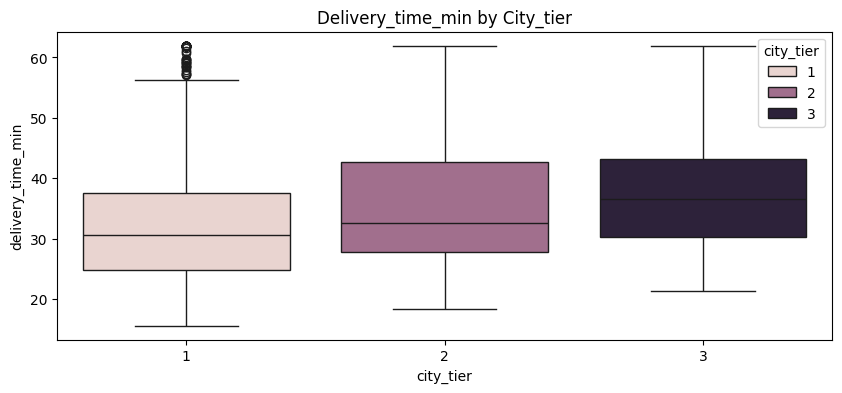

In [98]:
plt.figure(figsize=(10,4))

sns.boxplot(x = df['city_tier'],
            y = df['delivery_time_min'],
            hue = df['city_tier']
            )
plt.title("Delivery_time_min by City_tier")
plt.show()

**Observation**:

Comparing delivery times across city tiers reveals a clear stepwise slowdown from Tier 1 to Tier 3. Median delivery time increases steadily from roughly 30.5 minutes in Tier 1 to 32.5 minutes in Tier 2, and reaches 36.5 minutes in Tier 3—a 6-minute median gap between major metro areas and Tier 3 cities. Minimum delivery times also climb from 15.6 minutes in Tier 1 to over 21 minutes in Tier 3, pointing to longer travel distances or lower rider density in smaller cities. Notably, while all three tiers hit our 61.95-minute IQR cap at the top, only Tier 1 displays upper outlier dots above ~56.5 minutes due to its tighter overall spread.

---

- Question: Which variable has the strongest relationship with annual_spend ? Does correlation prove causation?

  Answer: orders_last_12m has the strongest relationship with annual_spend(corr of 0.72).

   No, correlation does not prove causation.

  ---
  ---
    

**Task 5: Encoding Categorical Variables**

Technique: Label encoding

Apply to: membership (Basic=0 ... Platinum=3)

Note: Order is meaningful, so label/ordinal encoding fits

In [99]:
le = LabelEncoder()
df['membership'] = le.fit_transform(df['membership'])

In [100]:
df['membership'].value_counts()

,count
membership,
0,1179
3,436
1,237
2,148


---

Technique: One-hot encoding

Apply to: device_type , acquisition_channel

Note: Use pd.get_dummies ; discuss the dummy variable trap ( drop_first )

In [101]:
df['device_type'].unique()

array(['Android', 'iOS', 'Web'], dtype=object)

In [102]:
pd.get_dummies(df['device_type'], drop_first=True, dtype='int').head()

,Web,iOS
0,0,0
1,0,1
2,0,1
3,0,0
4,0,0


In [103]:
df['acquisition_channel'].unique()

array(['Referral', 'Influencer', 'Paid Social', 'Search Ads', 'Organic'],
      dtype=object)

In [104]:
pd.get_dummies(df['acquisition_channel'], drop_first=True, dtype='int').head()

,Organic,Paid Social,Referral,Search Ads
0,0,0,1,0
1,0,0,0,0
2,0,0,1,0
3,0,1,0,0
4,0,0,0,1


In [105]:
df = pd.get_dummies(df, columns=['membership', 'acquisition_channel'], drop_first=True, dtype=int)

In [106]:
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,age,tenure_months,app_sessions_per_month,delivery_time_min,...,unsatisfactory_delivery,log_aov,month,membership_1,membership_2,membership_3,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,QB100000,2023-11-27,Lucknow,2,Female,Android,21.0,35.6,13,45.3,...,True,6.349139,2023-11,0,0,0,0,0,1,0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,43.0,17.4,11,21.9,...,False,5.796058,2025-05,0,0,0,0,0,0,0
2,QB100002,2023-02-06,Indore,3,Male,iOS,39.0,45.4,12,47.9,...,False,4.770685,2023-02,0,0,0,0,0,1,0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,34.0,31.2,13,26.4,...,True,5.713733,2024-04,0,0,0,0,1,0,0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,33.0,18.9,17,19.4,...,False,5.252273,2025-04,0,0,0,0,0,0,1


The dummy variable trap occurs when two or more one-hot encoded columns are perfectly collinear, meaning one column can be predicted with 100% accuracy from the others. Setting drop_first=True fixes this trap by removing one redundant category column to serve as the baseline reference.

---

Technique: Target encoding

Apply to: City

Note: Replace each city with the mean annual_spend of that city

In [107]:
df['city'].nunique()

10

In [108]:
df.groupby('city')['annual_spend'].agg('mean')

,annual_spend
city,
Bengaluru,12004.006803
Delhi,12152.446667
Hyderabad,18300.340249
Indore,10732.646259
Jaipur,10410.643357
Kochi,15739.561905
Lucknow,13939.898649
Mumbai,12020.796875
Nagpur,15515.557692


In [109]:
df['city_encoded'] = round(df.groupby('city')['annual_spend'].transform('mean'), 2)

In [110]:
df['city_encoded']

,city_encoded
0,13939.90
1,12004.01
2,10732.65
3,10410.64
4,12020.80
...,...
1995,10410.64
1996,12152.45
1997,12004.01
1998,10732.65


Discuss:
1. why label-encoding city alphabetically would be misleading
2. why one-hot on 10 cities is wide
3. what the risk of target encoding is (leakage; using the target to build the feature)

1. Label encoding assigns arbitrary integers (0, 1, 2, ..) alphabetically. For nominal categories with no natural ranking, this introduces false mathematical assumptions.

- Example: Assigning Bangalore = 0, Delhi = 1, and Mumbai = 2 confuses us or algorithm into thinking Mumbai > Delhi > Bangalore or that Mumbai is "twice" as large as Delhi

2. One-hot encoding creates a binary (0 or 1) column for every unique category. Encoding 10 cities turns 1 column into 10 columns (or 9 if using drop_first=True). Our dataset becomes massive, slows down training, and triggers the *curse of dimensionality*

3. Target encoding replaces each city with a mean of the target variable.
Leakage: Because we used the target variable to build the input feature, the feature directly absorbs information from the label it is trying to predict.


##### SIDE BY SIDE COMPARISON OF CITY FOR EACH ENCODING:

In [111]:
encode_df = pd.read_csv("quickbite_customers.csv", usecols=['city', 'annual_spend'])
encode_df.head()

,city,annual_spend
0,Lucknow,8675.0
1,Bengaluru,7896.0
2,Indore,1826.0
3,Jaipur,90202.0
4,Mumbai,2773.0


In [112]:
# label encoding:
le_city = LabelEncoder()
encode_df['label_encoded_city'] = le_city.fit_transform(encode_df['city'])

# onehot encoding:
ohe = pd.get_dummies(encode_df['city'], prefix='city', dtype=int) #not dropped first

# target encoding:
encode_df['target_encoded_city'] = encode_df.groupby('city')['annual_spend'].transform('mean')

# for side by side comparing concating ohe with encode df
pd.concat([encode_df, ohe], axis=1).iloc[:10, 2:]

,label_encoded_city,target_encoded_city,city_Bengaluru,city_Delhi,city_Hyderabad,city_Indore,city_Jaipur,city_Kochi,city_Lucknow,city_Mumbai,city_Nagpur,city_Pune
0,6,13939.898649,0,0,0,0,0,0,1,0,0,0
1,0,12004.006803,1,0,0,0,0,0,0,0,0,0
2,3,10732.646259,0,0,0,1,0,0,0,0,0,0
3,4,10410.643357,0,0,0,0,1,0,0,0,0,0
4,7,12020.796875,0,0,0,0,0,0,0,1,0,0
5,5,15739.561905,0,0,0,0,0,1,0,0,0,0
6,6,13939.898649,0,0,0,0,0,0,1,0,0,0
7,6,13939.898649,0,0,0,0,0,0,1,0,0,0
8,7,12020.796875,0,0,0,0,0,0,0,1,0,0
9,0,12004.006803,1,0,0,0,0,0,0,0,0,0


Suggestion: Mapping or Target encoding would be best choice to encode 'city', still OneHot Encoding also be a good choice if dataset has less columns.

---
---

**Task 6: Central Tendency and Percentiles**

- Compute mean, median, mode of age , orders_last_12m , annual_spend , and membership (mode only for categories).

In [113]:
print("Age Mean: ", df.age.mean())
print("Age Median: ", df.age.median())
print()
print("Orders_last_12m Mean: ", df.orders_last_12m.mean())
print("Orders_last_12m Median: ", df.orders_last_12m.median())
print()
print("Annual_spend  Mean: ", df.annual_spend.mean())
print("Annual_spend  Median: ", df.annual_spend.median())
print()
print("membership Mode: ", raw_df['membership'].mode()[0]) #membership is onehot encoded in df

Age Mean:  31.836
Age Median:  32.0

Orders_last_12m Mean:  34.8965
Orders_last_12m Median:  24.0

Annual_spend  Mean:  12995.852
Annual_spend  Median:  7142.0

membership Mode:  Basic


- Show why mean ≫ median for annual_spend and what that tells the business.

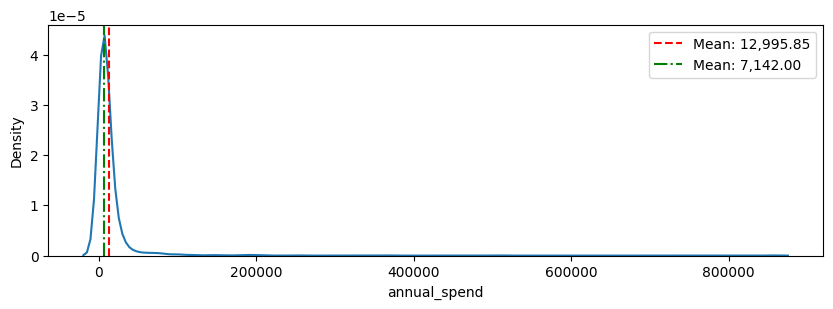

In [114]:
plt.figure(figsize=(10,3))
sns.kdeplot(df['annual_spend'])
plt.axvline(df.annual_spend.mean(), linestyle='--', color='red', label=f'Mean: {df.annual_spend.mean():,.2f}')
plt.axvline(df.annual_spend.median(), linestyle='-.', color='green', label=f'Mean: {df.annual_spend.median():,.2f}')
plt.legend()
plt.show()

Annual_spend  Mean:  12995.852

Annual_spend  Median:  7142.0

###### Here, the mean (12,995.85) is significantly higher than the median (7,142.00) because annual_spend is heavily right-skewed, following a classic Pareto pattern (the 80/20 rule). This means the majority of customers spend around the typical baseline, while a smaller segment of high-frequency or high-spending power users drives a disproportionate share of total revenue. Because this upper tail pulls the mean sharply to the right, the median is a much more reliable metric for representing a typical customer's annual spend.

---

- Compute percentiles (P10, P25, P50, P75, P90, P95, P99) of delivery_time_min and annual_spend .

In [115]:
print("PERCENTILES FOR Delivery_time_min:-")
print("P10: ", df.delivery_time_min.quantile(0.10))
print("P25: ", df.delivery_time_min.quantile(0.25))
print("P50: ", df.delivery_time_min.quantile(0.50))
print("P75: ", df.delivery_time_min.quantile(0.75))
print("P90: ", df.delivery_time_min.quantile(0.90))
print("P95: ", df.delivery_time_min.quantile(0.95))
print("P99: ", df.delivery_time_min.quantile(0.99))

PERCENTILES FOR Delivery_time_min:-
P10:  22.1
P25:  26.5
P50:  32.25
P75:  40.1
P90:  49.210000000000015
P95:  55.4
P99:  61.95


In [116]:
print("PERCENTILES FOR Annual_spend:-")
print("P10: ", df.annual_spend.quantile(0.10))
print("P25: ", df.annual_spend.quantile(0.25))
print("P50: ", df.annual_spend.quantile(0.50))
print("P75: ", df.annual_spend.quantile(0.75))
print("P90: ", df.annual_spend.quantile(0.90))
print("P95: ", df.annual_spend.quantile(0.95))
print("P99: ", df.annual_spend.quantile(0.99))

PERCENTILES FOR Annual_spend:-
P10:  2508.6
P25:  4085.75
P50:  7142.0
P75:  12781.25
P90:  22453.700000000008
P95:  35355.24999999999
P99:  109149.77999999997


---

- Draw a box plot and annotate quartiles

In [117]:
# A curated and dedicated function to visualise percentiles beyond P0,P25,P50,P75,P100
def boxplot_percentile(col):

  percentile = [10, 25, 50, 75, 90, 95, 99]
  colors = ['gray', 'blue', 'green', 'purple', 'orange', 'darkorange', 'red']
  per_value = np.percentile(col, percentile)
  plt.figure(figsize=(14,4))
  sns.boxplot(col, width=0.35, orient='h')

  for i, (p, p_val) in enumerate(zip(percentile, per_value)):
    plt.axvline(p_val, color=colors[i], linestyle='-.', alpha=0.75, linewidth=1.3)
    y_pos = -0.32 if i % 2 == 0 else 0.35

    plt.text(
        p_val,
        y_pos,
        f'P{p}: {p_val:,.1f}',
        color=colors[i],
        fontsize=8,
        fontweight='bold',
        ha='center',
        bbox=dict(
            facecolor='white', alpha=0.8, edgecolor='none', pad=1
        )  # Clean background box
    )

  plt.title(
      f'Distribution of {col.name} with Key Percentiles (P10 – P99)'
  )
  plt.xlabel(col.name)
  plt.tight_layout()
  plt.show()

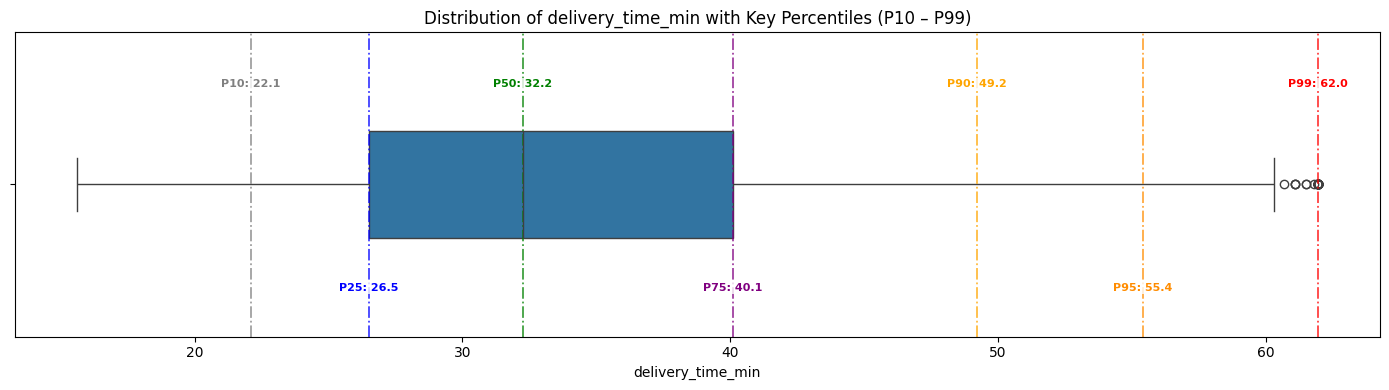

In [118]:
boxplot_percentile(df['delivery_time_min'])

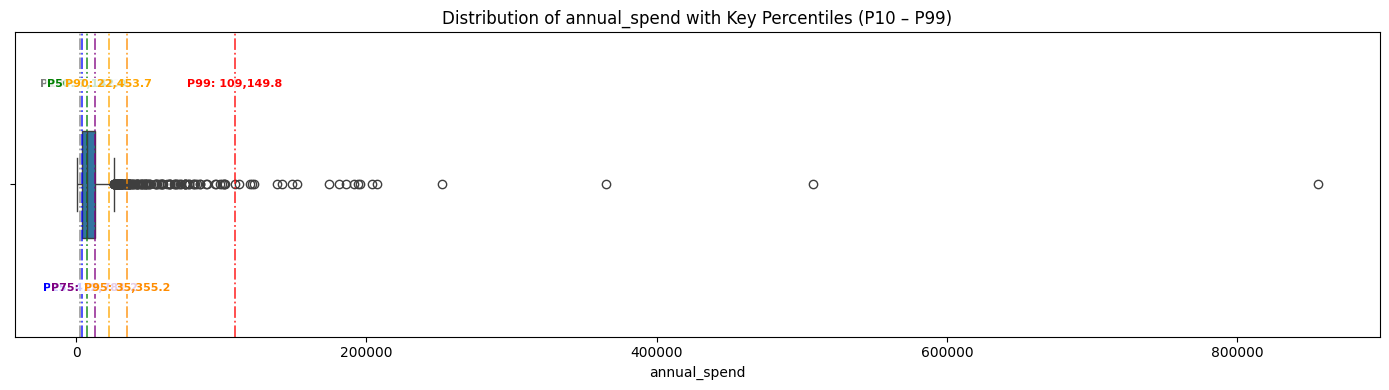

In [119]:
boxplot_percentile(df['annual_spend'])

- Business question: "What delivery time do 90% of customers experience or better?" (P90).

  ##### Based on the 90th percentile (P90 = 49.21 mins) calculated and boxplot above, 90% of customers receive their orders within 49.21 minutes or faster, while only 10% experience delays.

**Task 7: Pareto Distribution and the 80/20 Rule**

- Sort customers by annual_spend , compute cumulative revenue share.

In [120]:
df['annual_spend'].sort_values(ascending=False).head(5)

,annual_spend
236,855443.0
319,507406.0
687,364740.0
1686,251922.0
1830,207118.0


In [121]:
df['annual_spend'].sort_values(ascending=False).tail(5)

,annual_spend
1883,750.0
1360,676.0
1794,662.0
694,593.0
707,523.0


In [122]:
print("annual_spend max:", df.annual_spend.max())
print("annual_spend min:", df.annual_spend.min())

annual_spend max: 855443.0
annual_spend min: 523.0


In [123]:
# Sorting customers by annual_spend
sorted_customers= df.sort_values(by='annual_spend', ascending=False)[['customer_id', 'annual_spend']].reset_index(drop=True)
sorted_customers.head()
# calculating cumulative sum for each sorted customers
sorted_customers['cumsum'] = sorted_customers['annual_spend'].cumsum()
sorted_customers.head()

,customer_id,annual_spend,cumsum
0,QB100236,855443.0,855443.0
1,QB100319,507406.0,1362849.0
2,QB100687,364740.0,1727589.0
3,QB101686,251922.0,1979511.0
4,QB101830,207118.0,2186629.0


In [124]:
# Computing cumulative revenue share.
sorted_customers['cumulative_share'] = round(sorted_customers['cumsum']/sorted_customers['annual_spend'].sum()*100,3)
sorted_customers

,customer_id,annual_spend,cumsum,cumulative_share
0,QB100236,855443.0,855443.0,3.291
1,QB100319,507406.0,1362849.0,5.243
2,QB100687,364740.0,1727589.0,6.647
3,QB101686,251922.0,1979511.0,7.616
4,QB101830,207118.0,2186629.0,8.413
...,...,...,...,...
1995,QB101883,750.0,25989250.0,99.991
1996,QB101360,676.0,25989926.0,99.993
1997,QB101794,662.0,25990588.0,99.996
1998,QB100694,593.0,25991181.0,99.998


---

- Plot a Pareto chart (bars for spend, line for cumulative %) or a cumulative-share curve.

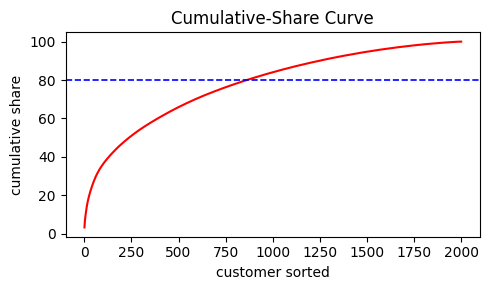

In [125]:
plt.figure(figsize=(5, 3))
sns.lineplot(sorted_customers, x=sorted_customers.index+1, y='cumulative_share', color='red')
plt.xlabel('customer sorted')
plt.ylabel('cumulative share')
plt.axhline(80, linestyle='--', color='blue', linewidth=1.2)
plt.title('Cumulative-Share Curve')
plt.tight_layout()
plt.show()


Takeaway (Pareto Analysis):

Looking at the cumulative revenue curve across all 2,000 customers:-
- Our revenue is heavily concentrated among a smaller group of high-spending power users.
- Our top 20% of customers (top 400) generate roughly 60% of total revenue, and 80% of total revenue comes from just the top ~850 customers (42.5%), while the remaining 57.5% contribute only 20% combined.
- Since losing even a few of these top spenders would hurt overall revenue significantly, we should focus on VIP retention perks for the top 20% while running targeted upsell campaigns to push middle-tier customers to spend more.

---

- Find what percentage of customers contribute 50% and 80% of revenue.

In [126]:
fifty_pct = sorted_customers['annual_spend'].sum()*0.5
eighty_pct = sorted_customers['annual_spend'].sum()*0.8
print(fifty_pct, '|', eighty_pct)

12995852.0 | 20793363.200000003


In [127]:
print("% of customers contribute 50% of Revenue: ",
      len(sorted_customers[sorted_customers['cumsum']<=fifty_pct])/len(sorted_customers)*100)
print("% of customers contribute 80% of Revenue: ",
      len(sorted_customers[sorted_customers['cumsum']<=eighty_pct])/len(sorted_customers)*100)

% of customers contribute 50% of Revenue:  11.85
% of customers contribute 80% of Revenue:  43.05


---

- Compare the top 20% share with the classic 80/20 idea.

  (In this dataset, the concentration is strong but you should report what you actually find.)

In [128]:
len(sorted_customers)*0.2 #400

400.0

In [129]:
print("20% of customer who spends more than 80% of total population:")
sorted_customers.iloc[400-1]

20% of customer who spends more than 80% of total population:


,399
customer_id,QB101972
annual_spend,14589.0
cumsum,15754552.0
cumulative_share,60.614


If we add up the spending of top **400 customers**, they bring in **60.61%** of the company's total money.

In [130]:
# if we've to reach 80% of total rev
sorted_customers[sorted_customers['cumulative_share']>=80].head() #861+1 customer helped reach threshold of 80%

,customer_id,annual_spend,cumsum,cumulative_share
861,QB101325,8160.0,20795138.0,80.007
862,QB101542,8160.0,20803298.0,80.038
863,QB101097,8156.0,20811454.0,80.070
864,QB101855,8151.0,20819605.0,80.101
865,QB101965,8131.0,20827736.0,80.132


In [131]:
862-400

462

(861 + 1) / 2000 * 100 = **43.1%**(more 462 customers)

Our top 20% of customers (top 400) generate 60.61% of total revenue, meaning we need 462 additional customers—bringing the total to 862 customers (43.1%)—to reach the 80% revenue threshold.


***Comparison with the Classic 80/20 Rule:***

Unlike the strict textbook **80/20** rule (where the top **20%** of customers generate **80%** of revenue), our dataset shows a **60.6 / 20** split. Specifically, our top **20%** of customers (**top 400**) generate **60.61% of total revenue**, while it takes **43.15%** of customers **(863 customers**) to reach the **80%** revenue mark. Even though the concentration isn't quite as extreme as **80/20**, a single fifth of our user base still drives over three-fifths of all revenue—confirming strong revenue concentration where retaining top spenders remains critical, while our middle segment still contributes a meaningful share of overall sales

---

- Plot annual_spend on a normal scale and a log scale and explain what changes.

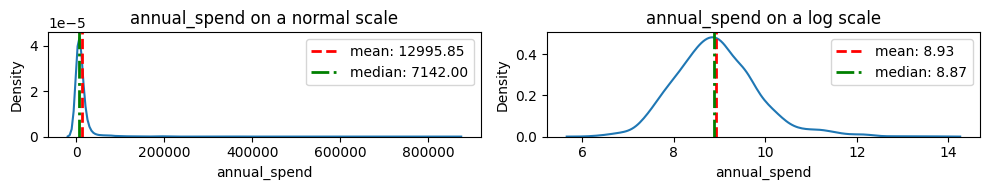

In [132]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,2))
sns.kdeplot(df['annual_spend'], ax=ax1)
sns.kdeplot(np.log(df['annual_spend']), ax=ax2)
ax1.set_title('annual_spend on a normal scale')
ax1.axvline(df['annual_spend'].mean(), linestyle='--', color='red', linewidth=2, label=f'mean: {df['annual_spend'].mean():.2f}')
ax1.axvline(df['annual_spend'].median(), linestyle='-.', color='green', linewidth=2, label=f'median: {df['annual_spend'].median():.2f}')
ax2.axvline(np.log(df['annual_spend']).mean(), linestyle='--', color='red', linewidth=2, label=f'mean: {np.log(df['annual_spend']).mean():.2f}')
ax2.axvline(np.log(df['annual_spend']).median(), linestyle='-.', color='green', linewidth=2, label=f'median: {np.log(df['annual_spend']).median():.2f}')
ax2.set_title('annual_spend on a log scale')
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()



Applying a log transformation to 'annual_spend' which demonstrating a Pareto (power-law) distribution compresses the massive right tail and stretches out the tightly packed lower values, turning a steep, L-shaped curve into a much more balanced, symmetrical shape (often resembling a bell curve or exponential distribution).

---
---

**Task 8: PDF and CDF**

- Plot the PDF (KDE or normalised histogram) of delivery_time_min .

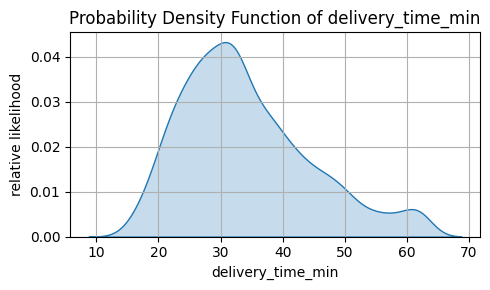

In [161]:
plt.figure(figsize=(5, 3))
sns.kdeplot(df['delivery_time_min'], fill=True)
plt.title('Probability Density Function of delivery_time_min')
plt.ylabel('relative likelihood')
plt.grid() #to exactly trace points from x to y
plt.tight_layout()
plt.show()

*Probabilty Density Function shape observation:*

The PDF is **moderately right-skewed** distribution with a clear peak centered around 32.2 minutes, confirming that the vast majority of deliveries cluster tightly in the 25 to 35 minute window. The curve drops off sharply on the left and tapers gradually to the right, reflecting occasional peak-hour delays. Notably, a small secondary bump appears right near 62 minutes, visually reflecting the stacked values at our 61.95-minute IQR cap from outlier treatment(100-500mins).

- Plot the empirical CDF ( np.sort + np.arange(1, n+1)/n ).

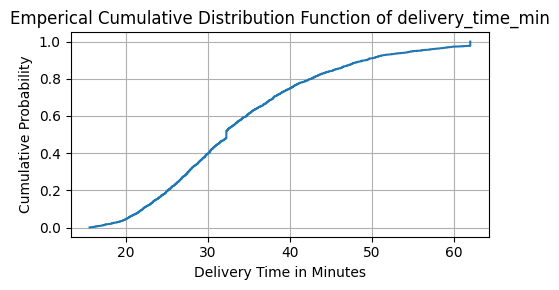

In [134]:
n = len(df)
x = np.sort(df['delivery_time_min'])
y = np.arange(1, n+1)/n

plt.figure(figsize=(5,3))
plt.plot(x, y)
plt.grid()
plt.xlabel('Delivery Time in Minutes')
plt.ylabel('Cumulative Probability', fontsize=10)
plt.title('Emperical Cumulative Distribution Function of delivery_time_min')
plt.tight_layout()
plt.show()


*Cumulative Distribution Function shape observation:*

Our curve rises smoothly from our **15.6-minute minimum** to our **61.95-minute upper limit**, making it easy to read exact delivery benchmarks—about** 41% of deliveries arrive within 30 minutes**, **half arrive by 32.25 minutes (P50), and 90% arrive within 49.21 minutes (P90)**.

Two preprocessing artifacts stand out clearly as sharp vertical jumps: a small step right at **32.25 minutes from our median imputation of missing entries**, and a **vertical wall at 61.95 minutes where all upper outliers were capped at the IQR boundary**

---

   Questions from above CDF:
   - What is the probability a delivery takes ≤ 30 minutes?

Based on CDF plot its roughly(not exactly) 0.4 or 40%. Lets calculate exact probability below.

In [135]:
len(df[df['delivery_time_min']<=30])/len(df)
# or (df['delivery_time_min']<=30).mean()

0.3985

Probability a delivery takes less than or exactly **30** minutes is **0.3985** or **39.85%**.

---

- What is the probability a delivery takes > 45 minutes?

In [136]:
(df['delivery_time_min']>45).mean()

np.float64(0.158)

Probability a delivery takes more than **45** minutes is **0.158** or **15.8%**.

---

- What time corresponds to the median and the 95th percentile?

  32.25 minutes for 50th Percentile(median)

  55.4 minutes for 95th Percentile

In [137]:
percentile=[50, 95]
print(f"50th Percentile corresponds to {np.percentile(df['delivery_time_min'], percentile)[0]} minutes")
print(f"95th Percentile corresponds to {np.percentile(df['delivery_time_min'], percentile)[1]} minutes")

50th Percentile corresponds to 32.25 minutes
95th Percentile corresponds to 55.4 minutes


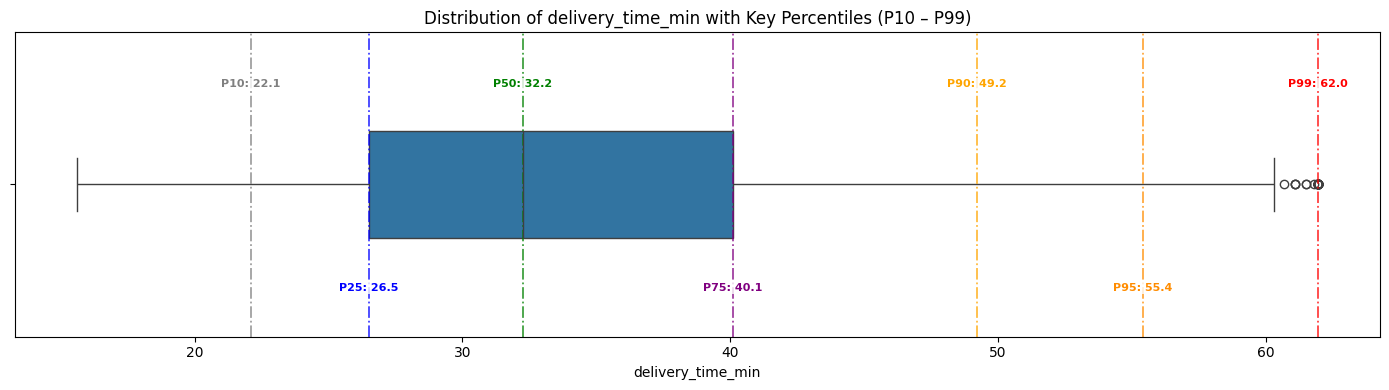

In [138]:
# Referring to TASK-6 Boxplot sub-task
boxplot_percentile(df['delivery_time_min'])

---

- Repeat for age (normal) and compare the CDF shapes.

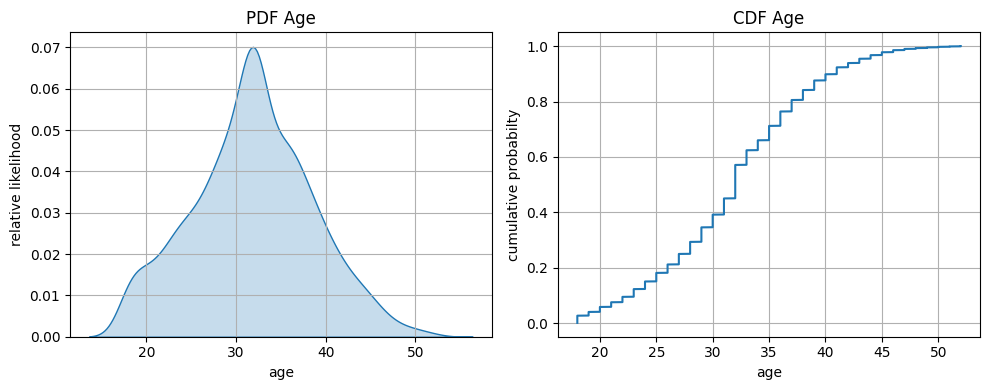

In [160]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
sns.kdeplot(df['age'], fill=True, ax=ax1)
ax2.plot(np.sort(df['age']), np.arange(1, len(df)+1)/len(df))
ax1.set_title('PDF Age')
ax1.set_ylabel('relative likelihood')
ax2.set_title('CDF Age')
ax2.set_xlabel('age')
ax2.set_ylabel('cumulative probabilty')
ax1.grid()
ax2.grid()
plt.tight_layout()
plt.show()

*Probabilty Density Function shape observation:*

The PDF shows a balanced, **symmetrical bell-shaped curve** with a sharp peak around **age 32**, confirming that our customer base is concentrated in their late 20s to mid-30s with virtually zero skew.

*Cumulative Distribution Function shape observation:*

We see the upward S-shaped curve rising from **0.0 to 1.0** between **ages 18 and 52**. Instead of a smooth line, the CDF forms a **staircase (step-shaped) pattern** because age is recorded in whole integers(Discrete Variable) with the largest vertical jump appearing right at **age 32** due to the high concentration of customers and our median-imputed entries sitting at that value.

---

- Explain in plain language:

  - PDF = how dense values are around a point

    Wherever the curve rises highest, that is where most data points fall. For example, *on our age PDF, the tall peak around 32 tells us that most of our restaurant customers are in their early 30s, while very few are near 18 or 50*
  
  - CDF = share of values at or below a point.

    Instead of looking for peaks, we read it from 0% to 100% to answer "how many" questions. For example, *on our delivery_time_min CDF, tracing up from 49.2 minutes hits 0.90 (90%), which simply means 90% of our customers receive their food in 49.2 minutes or less*.

    ---
    ---

In [146]:
# clean final dataset
print(df.info())
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   customer_id                      2000 non-null   object        
 1   signup_date                      2000 non-null   datetime64[ns]
 2   city                             2000 non-null   object        
 3   city_tier                        2000 non-null   int64         
 4   gender                           2000 non-null   object        
 5   device_type                      2000 non-null   object        
 6   age                              2000 non-null   float64       
 7   tenure_months                    2000 non-null   float64       
 8   app_sessions_per_month           2000 non-null   int64         
 9   delivery_time_min                2000 non-null   float64       
 10  avg_order_value                  2000 non-null   float64    

In [152]:
# dropping columns
clean_quickbite = df.drop(['unsatisfactory_delivery',
                           'month'], axis=1) #retained og annual_spend, log normal annual_spend and non-encoded city

In [155]:
clean_quickbite.to_csv('clean_quickbite.csv', index=False)

In [157]:
pd.read_csv('clean_quickbite.csv').head()

,customer_id,signup_date,city,city_tier,gender,device_type,age,tenure_months,app_sessions_per_month,delivery_time_min,...,annual_spend,log_aov,membership_1,membership_2,membership_3,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads,city_encoded
0,QB100000,2023-11-27,Lucknow,2,Female,Android,21.0,35.6,13,45.3,...,8675.0,6.349139,0,0,0,0,0,1,0,13939.90
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,43.0,17.4,11,21.9,...,7896.0,5.796058,0,0,0,0,0,0,0,12004.01
2,QB100002,2023-02-06,Indore,3,Male,iOS,39.0,45.4,12,47.9,...,1826.0,4.770685,0,0,0,0,0,1,0,10732.65
3,QB100003,2024-04-09,Jaipur,2,Female,Android,34.0,31.2,13,26.4,...,90202.0,5.713733,0,0,0,0,1,0,0,10410.64
4,QB100004,2025-04-12,Mumbai,1,Male,Android,33.0,18.9,17,19.4,...,2773.0,5.252273,0,0,0,0,0,0,1,12020.80


---
---
**OVERALL EXPLORATORY DATA ANALYSIS(Coding, Graphs and Observations)**

**CONDUCTED BY NIKHIL KUSHWAHA**

*DATA ANALYST AT QUICKBITES*

---
---

